# 🚗 Araç Hasar Tespit Sistemi — Tez Pipeline v4

> Sigorta sektöründe hasar tespitinin derin öğrenme ile otomasyonu

---

## 🏗️ Sistem Mimarisi

```
                    [Hasarlı Araç Fotoğrafı]
                              │
              ┌───────────────┴───────────────┐
              ▼                               ▼
   ┌────────────────────┐         ┌────────────────────┐
   │  MODEL 1: KONUM    │         │  MODEL 2: HASAR    │
   │  Carparts-Seg      │         │  Kendi Verim       │
   │  23 → 8 parça      │         │  Cizik/Gocuk/Kirik │
   │  640px             │         │  960px + Tiling    │
   └────────────────────┘         └────────────────────┘
              │                               │
              └───────────────┬───────────────┘
                              ▼
                  ┌───────────────────────┐
                  │   FÜZYON (Örtüşme)    │
                  │  Tampon-Kirik         │
                  │  Camurluk-Cizik       │
                  └───────────────────────┘
                              │
              ┌───────────────┴───────────────┐
              ▼                               ▼
     ┌─────────────────┐            ┌──────────────────┐
     │  GÖRSEL ÇIKTI   │            │  TRAMER RAPORU   │
     │  3 panel        │            │  PDF belge       │
     └─────────────────┘            └──────────────────┘
```

---

## ⚙️ Çalıştırma Sırası

| Hücre | İçerik | Süre |
|---|---|---|
| **0** | Google Drive bağlantısı | 1 dk |
| **1** | Kurulum + tüm ayarlar | 2 dk |
| **2** | Konum veri seti kontrolü | 2 dk |
| **3** | Model 1 eğitimi (konum, 640px) | ~40 dk |
| **4** | Hasar verisi indir (1024px version) | ~10 dk |
| **4A** | Harici veri birleştir (opsiyonel) | ~10 dk |
| **4D** | 🧩 Tiling — görselleri böl | ~20 dk |
| **4B** | Küçük annotation filtresi | ~3 dk |
| **4C** | Split düzelt (70/20/10) | ~3 dk |
| **5** | Model 2 eğitimi (hasar, 960px) | ~4-5 saat |
| **6** | Karşılaştırma tablosu | 2 dk |
| **6B** | Confusion matrix + detay metrikler | 5 dk |
| **6C** | K-fold (opsiyonel, en son) | ~5 saat |
| **6D** | ⚡ Drive'dan model yükle (eğitimi atla) | 2 dk |
| **7** | Füzyon motoru | 1 dk |
| **8** | Tek görsel testi | 1 dk |
| **9** | TRAMER PDF raporu | 2 dk |
| **10** | Toplu işlem + Excel | Değişken |

---

## 🔀 İki Kullanım Modu

**🔨 İlk kez (eğitim):** `0 → 1 → 2 → 3 → 4 → 4A → 4D → 4B → 4C → 5 → 6 → 6B`

**⚡ Sonra (model hazır):** `0 → 1 → 6D → 7 → 8/9/10`

---

> ⚡ **Colab Pro:** Runtime → Change runtime type → **A100 GPU** + **High-RAM**


---
## 💾 HÜCRE 0: Google Drive Bağlantısı

⚠️ **İLK ÇALIŞTIR.** Session kapanınca `/content` silinir; bu hücre her şeyi Drive'a kaydeder.


In [1]:
# ═══════════════════════════════════════════════════════════════════════════════
# 💾 HÜCRE 0: GOOGLE DRIVE BAĞLANTISI
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NEDEN GEREKLİ?
#    Colab session kapanınca /content silinir. Eğitilen modeller kaybolur.
#    Bu hücre her şeyi Drive'a kaydeder → bir kez eğit, sonsuza kadar kullan.
#
# 📁 DRIVE KLASÖR YAPISI:
#    MyDrive/tez_arac_hasar/
#       ├── modeller/          ← Eğitilen tüm modeller (.pt)
#       ├── ciktilar/          ← Grafikler, Excel, PDF raporlar
#       └── karsilastirma_sonuclari.json
# ═══════════════════════════════════════════════════════════════════════════════

import os

DRIVE_KULLAN = True   # False yaparsan sadece geçici diske kaydeder

if DRIVE_KULLAN:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ANA_DIZIN = '/content/drive/MyDrive/tez_arac_hasar'
        print('✅ Drive bağlandı')
    except Exception as e:
        print(f'⚠️ Drive bağlanamadı: {str(e)[:80]}')
        print('   Geçici diske kaydedilecek (session kapanınca silinir!)')
        ANA_DIZIN = '/content/tez_arac_hasar'
else:
    ANA_DIZIN = '/content/tez_arac_hasar'
    print('⚠️ Drive kullanılmıyor — modeller session sonunda silinecek!')

# ─── KLASÖRLERİ OLUŞTUR ───────────────────────────────────────────────────────
MODEL_DIZIN = os.path.join(ANA_DIZIN, 'modeller')
OUTPUT_DIR  = os.path.join(ANA_DIZIN, 'ciktilar')
RAPOR_DIR   = os.path.join(OUTPUT_DIR, 'raporlar')
GORSEL_DIR  = os.path.join(OUTPUT_DIR, 'gorseller')

for d in [ANA_DIZIN, MODEL_DIZIN, OUTPUT_DIR, RAPOR_DIR, GORSEL_DIR]:
    os.makedirs(d, exist_ok=True)

SONUC_JSON = os.path.join(ANA_DIZIN, 'karsilastirma_sonuclari.json')

print()
print('=' * 70)
print('📁 KLASÖR YAPISI')
print('=' * 70)
print(f'   Ana dizin : {ANA_DIZIN}')
print(f'   Modeller  : {MODEL_DIZIN}')
print(f'   Çıktılar  : {OUTPUT_DIR}')
print(f'   Sonuç JSON: {SONUC_JSON}')

# ─── DİSK DURUMU ──────────────────────────────────────────────────────────────
import shutil as _sh
_t, _k, _bos = _sh.disk_usage('/content')
print(f'\n💾 Geçici disk: {_bos/1e9:.1f} GB boş / {_t/1e9:.1f} GB toplam')
if _bos / 1e9 < 15:
    print('   ⚠️ Tiling için az olabilir. ORIJINALI_TUT=False öneriliyor.')

# ─── MEVCUT MODELLERİ KONTROL ET ──────────────────────────────────────────────
print()
print('=' * 70)
print('🔍 MEVCUT MODELLER')
print('=' * 70)

import glob, json as _json

bulunan = glob.glob(f'{MODEL_DIZIN}/**/weights/best.pt', recursive=True)
if bulunan:
    for mp in sorted(bulunan):
        ad = mp.split('/')[-3]
        boyut = os.path.getsize(mp) / 1e6
        print(f'   ✅ {ad:38s} ({boyut:6.1f} MB)')
    print(f'\n   💡 Bu modeller tekrar eğitilmeyecek — Hücre 5 otomatik atlar.')
    print(f'   ⚡ Sadece kullanmak istersen: Hücre 1 → 6D → 7')
else:
    print('   (henüz model yok — Hücre 3 ve 5 ile eğitilecek)')

if os.path.exists(SONUC_JSON):
    with open(SONUC_JSON) as f:
        _s = _json.load(f)
    if _s:
        print(f'\n   📊 Kayıtlı karşılaştırma: {len(_s)} model')
        for k, v in sorted(_s.items(), key=lambda x: -x[1].get('mask_mAP50', 0)):
            print(f'      {v.get("ad", k):32s} mAP50={v.get("mask_mAP50", 0):.4f}')

print('=' * 70)


Mounted at /content/drive
✅ Drive bağlandı

📁 KLASÖR YAPISI
   Ana dizin : /content/drive/MyDrive/tez_arac_hasar
   Modeller  : /content/drive/MyDrive/tez_arac_hasar/modeller
   Çıktılar  : /content/drive/MyDrive/tez_arac_hasar/ciktilar
   Sonuç JSON: /content/drive/MyDrive/tez_arac_hasar/karsilastirma_sonuclari.json

💾 Geçici disk: 202.9 GB boş / 253.1 GB toplam

🔍 MEVCUT MODELLER
   ✅ hasar_yolo11l-seg                      (  55.8 MB)
   ✅ hasar_yolo11m-seg                      (  45.2 MB)
   ✅ hasar_yolo11m-seg_sadece_kendi_veri    (  45.2 MB)
   ✅ hasar_yolo11n-seg                      (   6.0 MB)
   ✅ hasar_yolo11s-seg                      (  20.5 MB)
   ✅ hasar_yolov8m-seg                      (  54.8 MB)
   ✅ kfold_yolo11m-seg_f1                   (  45.2 MB)
   ✅ kfold_yolo11m-seg_f2                   (  45.2 MB)
   ✅ kfold_yolo11m-seg_f3                   (  45.2 MB)
   ✅ kfold_yolo11m-seg_f4                   ( 179.7 MB)
   ✅ konum                                  (  45.2 MB)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 💾 ADIM 1: MEVCUT SONUÇLARI YEDEKLE
# ═══════════════════════════════════════════════════════════════════════════════
# ⚠️ Yeni eğitim eskinin üzerine yazacak. Karşılaştırma yapabilmek için önce yedekle.
# ⚠️ Bu hücreyi Hücre 0'DAN SONRA çalıştır (ANA_DIZIN tanımlı olmalı).
# ═══════════════════════════════════════════════════════════════════════════════

import shutil, os, json, glob
from datetime import datetime

if 'ANA_DIZIN' not in globals():
    raise RuntimeError('❌ Önce HÜCRE 0\'ı çalıştır!')

ETIKET = f'v1_45epoch_{datetime.now().strftime("%Y%m%d_%H%M")}'
YEDEK = os.path.join(ANA_DIZIN, 'yedekler', ETIKET)
os.makedirs(YEDEK, exist_ok=True)

print('=' * 70)
print(f'💾 YEDEKLEME: {ETIKET}')
print('=' * 70)

# 1. Sonuç JSON
if os.path.exists(SONUC_JSON):
    shutil.copy(SONUC_JSON, os.path.join(YEDEK, 'karsilastirma_sonuclari.json'))
    with open(SONUC_JSON) as f:
        _eski = json.load(f)
    print(f'✅ Sonuç JSON yedeklendi ({len(_eski)} model)')
    for k, v in _eski.items():
        print(f'   {v.get("ad","?"):22s} mAP50={v.get("mask_mAP50",0):.4f}')

# 2. Çıktılar (grafikler, Excel, LaTeX)
sayac = 0
if os.path.exists(OUTPUT_DIR):
    for f in os.listdir(OUTPUT_DIR):
        p = os.path.join(OUTPUT_DIR, f)
        if os.path.isfile(p):
            shutil.copy(p, os.path.join(YEDEK, f))
            sayac += 1
    print(f'✅ {sayac} çıktı dosyası yedeklendi')

# 3. Model ağırlıkları
for mp in glob.glob(f'{MODEL_DIZIN}/hasar_*/weights/best.pt'):
    ad = mp.split('/')[-3]
    boyut = os.path.getsize(mp) / 1e6
    shutil.copy(mp, os.path.join(YEDEK, f'{ad}_best.pt'))
    print(f'✅ Model yedeklendi: {ad} ({boyut:.1f} MB)')

# 4. Sonuç JSON'unu SIFIRLA
with open(SONUC_JSON, 'w') as f:
    json.dump({}, f)

print()
print('=' * 70)
print(f'📦 Yedek: {YEDEK}')
print(f'🔄 Sonuç JSON sıfırlandı — yeni eğitim temiz başlayacak')
print('=' * 70)
print('\n➡️  SONRAKİ: Hücre 1 (yeni ayarlarla) → 4 → 4A → 4D → 4B → 4C → 5')

💾 YEDEKLEME: v1_45epoch_20260804_1747
✅ Sonuç JSON yedeklendi (6 model)
   YOLOv11-Nano           mAP50=0.3442
   YOLOv11-Small          mAP50=0.3344
   YOLOv11-Medium         mAP50=0.4325
   YOLOv11-Large          mAP50=0.4279
   YOLOv8-Medium          mAP50=0.3675
   YOLOv11-Medium         mAP50=0.5918
✅ 15 çıktı dosyası yedeklendi
✅ Model yedeklendi: hasar_yolo11n-seg (6.0 MB)
✅ Model yedeklendi: hasar_yolo11s-seg (20.5 MB)
✅ Model yedeklendi: hasar_yolo11m-seg (45.2 MB)
✅ Model yedeklendi: hasar_yolo11l-seg (55.8 MB)
✅ Model yedeklendi: hasar_yolov8m-seg (54.8 MB)
✅ Model yedeklendi: hasar_yolo11m-seg_sadece_kendi_veri (45.2 MB)

📦 Yedek: /content/drive/MyDrive/tez_arac_hasar/yedekler/v1_45epoch_20260804_1747
🔄 Sonuç JSON sıfırlandı — yeni eğitim temiz başlayacak

➡️  SONRAKİ: Hücre 1 (yeni ayarlarla) → 4 → 4A → 4D → 4B → 4C → 5


---
## 🔧 HÜCRE 1: Kurulum + Tüm Ayarlar

⚠️ **API key'ini buraya gir.** Tüm parametreler bu hücrede toplandı.


In [2]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔧 HÜCRE 1: KURULUM + GLOBAL AYARLAR
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v4 GÜNCELLEMELERİ:
#    - IMG_SIZE 640 → 960 (ince çizikler için)
#    - KONUM_* ayrıldı (parçalar büyük nesne → 640 yeterli, OOM önlenir)
#    - ZORLA_YENI_VERSION (1024'lük Roboflow version'u)
#    - TILE_* ayarları (görsel bölme → çizikler büyür)
#    - MIN_ANNOTATION_ALAN (çok küçük annotation'lar model'i bozuyor)
# ═══════════════════════════════════════════════════════════════════════════════

!pip install ultralytics roboflow reportlab openpyxl shapely -q

import os, torch, warnings
warnings.filterwarnings('ignore')

# ═══ ROBOFLOW ══════════════════════════════════════════════════════════════════
API_KEY        = os.environ['ROBOFLOW_API_KEY']        # ⚠️ MUTLAKA DOLDUR
WORKSPACE      = 'burhans-workspace-fev5o'
HASAR_PROJECT  = 'my-first-project-2-llolj-0rqmz'

# ⚠️ VERSION — ÇOK ÖNEMLİ
#    Eski v1 = 640x640 → 960 eğitimi ANLAMSIZ olur (YOLO büyütür, detay gelmez)
#    Yeni     = 1024x1024 → ZORLA_YENI_VERSION=True ile oluşturulur
HASAR_VERSION       = None    # None = en son version
ZORLA_YENI_VERSION  = True    # True = 1024'lük yeni version oluştur

# ═══ MODEL 1: KONUM (PARÇA) ════════════════════════════════════════════════════
KONUM_DATASET = 'carparts-seg.yaml'   # Ultralytics resmi, 3833 görsel, 23 sınıf

KONUM_MAP = {
    'back_bumper': 'Tampon',       'front_bumper': 'Tampon',
    'back_glass':  'Cam',          'front_glass':  'Cam',
    'back_left_door':   'Kapi',    'back_right_door':  'Kapi',
    'front_left_door':  'Kapi',    'front_right_door': 'Kapi',
    'back_left_light':  'Far',     'back_right_light': 'Far',
    'front_left_light': 'Far',     'front_right_light':'Far',
    'hood':        'Kaput',
    'left_mirror': 'Dikiz-Ayna',   'right_mirror': 'Dikiz-Ayna',
    'tailgate':    'Bagaj',        'trunk':        'Bagaj',
    'wheel':       'Camurluk',
}
KONUM_SINIFLAR = ['Tampon','Kaput','Kapi','Camurluk','Bagaj','Far','Cam','Dikiz-Ayna']

# Parçalar BÜYÜK nesneler → 960 gereksiz, 640 yeterli + 3x hızlı + OOM yok
KONUM_IMG_SIZE = 640
KONUM_EPOCHS   = 60
KONUM_BATCH    = 12

# ═══ MODEL 2: HASAR TİPİ ═══════════════════════════════════════════════════════
HASAR_MAP = {
    'cizik-hasari':'Cizik', 'cizik-hasar':'Cizik', 'cizik':'Cizik',
    'gocuk-hasari':'Gocuk', 'gocuk-hasar':'Gocuk', 'gocuk':'Gocuk',
    'kirik-hasari':'Kirik', 'kirik-hasar':'Kirik', 'kirik':'Kirik',
}
HASAR_SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

# ─── Karşılaştırılacak modeller ───────────────────────────────────────────────
# 💡 ÖNCE SADECE MEDIUM. Sonuç iyiyse diğerlerinin yorumunu kaldır.
# ⚠️ 960px çok VRAM yiyor → batch düşük
KARSILASTIRMA_MODELLERI = [
    ('yolo11m-seg', 'YOLOv11-Medium', 8),
    # ('yolo11n-seg', 'YOLOv11-Nano',   16),
    # ('yolo11s-seg', 'YOLOv11-Small',  12),
    # ('yolo11l-seg', 'YOLOv11-Large',   6),
    # ('yolov8m-seg', 'YOLOv8-Medium',   8),
]

# ─── Eğitim parametreleri ─────────────────────────────────────────────────────
# ⚠️ TILING AÇIKSA veri ~4-5x artar → EPOCHS'u düşük tut!
#    Tiling + 100 epoch = ~15 saat (çok uzun)
#    Tiling +  45 epoch = ~5 saat (makul)
EPOCHS     = 45
IMG_SIZE   = 960
PATIENCE   = 15

# ═══ VERİ KALİTESİ FİLTRESİ (Hücre 4B) ═════════════════════════════════════════
# Çok küçük çizikler YOLO'nun en ince katmanına bile sığmıyor.
# Model öğrenemez ama loss cezası alır → BÜYÜK çizikleri de kaçırır.
MIN_ANNOTATION_ALAN = 0.0004   # Görselin %0.04'ü
                                # Bir sınıfın %40+'ı silinirse 0.0002 yap

# ═══ TILING — GÖRSEL BÖLME (Hücre 4D) ══════════════════════════════════════════
# 🎯 AMAÇ: İnce çizikleri büyütmek
#    1024px görselde 15px çizik → 2x2 böl → 512px tile → YOLO 960'a büyütür
#    Sonuç: çizik ~28px olur (1.9x) → model artık görebiliyor
#
# ⚠️ VERİ ARTIŞI: (2,2) → ~4-5x | (3,3) → ~9-10x
TILE_UYGULA     = True
TILE_GRID       = (2, 2)      # (satır, sütun)
TILE_OVERLAP    = 0.20        # %20 örtüşme (sınırdaki hasarlar kaybolmasın)
ORIJINALI_TUT   = False       # ⚠️ False = disk ve süre tasarrufu (önerilen)
MIN_POLY_ORAN   = 0.30        # Kırpılan polygon orijinalin %30'undan azsa at
MIN_TILE_ALAN   = 0.0008      # Tile içinde bu orandan küçük annotation at
BOS_TILE_ORANI  = 0.10        # Hasarsız tile'ların %10'u negatif örnek

# ═══ HARİCİ VERİ (Hücre 4A) ════════════════════════════════════════════════════
HARICI_VERI_EKLE = True
HARICI_KAYNAKLAR = [
    ('sinfo', 'car-damage-segmentation', None),   # 4303 görsel, instance seg
]
HARICI_MAP = {
    'scratch':'Cizik', 'scratches':'Cizik', 'cizik':'Cizik',
    'minor-scratches':'Cizik', 'scratch-damage':'Cizik',
    'dent':'Gocuk', 'dents':'Gocuk', 'gocuk':'Gocuk',
    'dent-damage':'Gocuk', 'deformation':'Gocuk',
    'crack':'Kirik', 'cracks':'Kirik', 'kirik':'Kirik',
    'glass-shatter':'Kirik', 'glass shatter':'Kirik',
    'broken':'Kirik', 'lamp-broken':'Kirik', 'shatter':'Kirik',
}

# ═══ FÜZYON (Hücre 7) ══════════════════════════════════════════════════════════
KONUM_CONF = 0.30    # Parça tespiti min güven
HASAR_CONF = 0.30    # Hasar tespiti min güven
FUZYON_IOU = 0.10    # Hasar-parça min örtüşme

# NOT: MODEL_DIZIN, OUTPUT_DIR, RAPOR_DIR, GORSEL_DIR, SONUC_JSON → HÜCRE 0'da

# ═══ GPU KONTROL + ÖZET ════════════════════════════════════════════════════════
print('=' * 70)
print('🔧 KURULUM TAMAMLANDI')
print('=' * 70)
print(f'PyTorch : {torch.__version__}')
if torch.cuda.is_available():
    gn = torch.cuda.get_device_name(0)
    gm = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU     : {gn} ({gm:.1f} GB)')
    DEVICE = 0
    if 'A100' not in gn and IMG_SIZE >= 960:
        print(f'   ⚠️ A100 değil — 960px için batch düşürmen gerekebilir')
else:
    print('⚠️  GPU YOK — eğitim çok yavaş olur!')
    DEVICE = 'cpu'

if API_KEY == 'BURAYA_API_KEY_YAZ':
    print('\n' + '❌' * 25)
    print('API_KEY DOLDURULMAMIŞ! Hücre 1\'in başına Roboflow key\'ini yaz.')
    print(f'   https://app.roboflow.com/{WORKSPACE}/settings/api')
    print('❌' * 25)

print()
print('⚙️  MODEL 1 (KONUM):')
print(f'   {KONUM_IMG_SIZE}px | {KONUM_EPOCHS} epoch | batch {KONUM_BATCH}')
print()
print('⚙️  MODEL 2 (HASAR):')
print(f'   {IMG_SIZE}px | {EPOCHS} epoch | patience {PATIENCE}')
print(f'   Sınıflar: {HASAR_SINIFLAR}')
print(f'   Modeller: {[m[1] for m in KARSILASTIRMA_MODELLERI]}')
print()
print('🧩 TILING:')
if TILE_UYGULA:
    _n = TILE_GRID[0] * TILE_GRID[1]
    _carpan = _n + (1 if ORIJINALI_TUT else 0)
    print(f'   {TILE_GRID[0]}x{TILE_GRID[1]} = {_n} parça | örtüşme %{TILE_OVERLAP*100:.0f}')
    print(f'   Orijinal: {"korunacak" if ORIJINALI_TUT else "silinecek"}')
    print(f'   ⚠️ Veri ~{_carpan}x artacak → eğitim de ~{_carpan}x uzayacak')
    print(f'   💡 Çizikler ~{_n**0.5:.1f}x büyüyecek')
else:
    print('   ⏭️  KAPALI')
print()
print('🌐 HARİCİ VERİ:', 'AÇIK' if HARICI_VERI_EKLE else 'KAPALI')
print()
if ZORLA_YENI_VERSION:
    print('🔄 ZORLA_YENI_VERSION = True')
    print('   → Hücre 4, 1024x1024 YENİ version oluşturacak')
    print('   → 960 eğitiminin işe yaraması için ŞART')
else:
    print('⚠️  ZORLA_YENI_VERSION = False → mevcut version kullanılacak')
print('=' * 70)

# ─── TAHMİNİ SÜRE ─────────────────────────────────────────────────────────────
_tahmini = EPOCHS * 5.5 * (TILE_GRID[0]*TILE_GRID[1] if TILE_UYGULA else 1) / 4
print(f'\n⏱️  TAHMİNİ EĞİTİM SÜRESİ (Model 2): ~{_tahmini:.0f} dakika '
      f'({_tahmini/60:.1f} saat)')
print('   (A100 varsayımı — V100/T4\'te 1.5-2.5x uzar)')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 84.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 285.0/285.0 kB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 104.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 77.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.7 MB/s eta 0:00:00
🔧 KURULUM TAMAMLANDI
PyTorch : 2.11.0+cu128
GPU     : NVIDIA A100-SXM4-80GB (85.1 GB)

⚙️  MODEL 1 (KONUM):
   640px | 60 epoch | batch 12

⚙️  MODEL 2 (HASAR):
   960px | 45 epoch | patience 15
   Sınıflar: ['Cizik', 'Gocuk', 'Kirik']
   Modeller: ['YOLOv11-Medium']

🧩 TILING:
   2x2 = 4 parça | örtüşme %20
   Orijinal: silinecek
   ⚠️ Veri ~4x artacak → eğitim de ~4x u

In [3]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔧 HÜCRE 1-v2: KURULUM + GLOBAL AYARLAR
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v5 GÜNCELLEMELERİ (uzun eğitim + yanlış pozitif azaltma):
#    - EPOCHS 45 → 120 (eğriler doygunluğa ulaşmamıştı)
#    - PATIENCE 15 → 40 (erken durmasın)
#    - BOS_TILE_ORANI 0.10 → 0.25 (yanlış pozitif azaltma)
#    - HASAR_CONF 0.30 → 0.33 (F1 eğrisinin optimal noktası)
# ═══════════════════════════════════════════════════════════════════════════════

!pip install ultralytics roboflow reportlab openpyxl shapely -q

import os, torch, warnings
warnings.filterwarnings('ignore')

# ═══ ROBOFLOW ══════════════════════════════════════════════════════════════════
API_KEY        = os.environ['ROBOFLOW_API_KEY']        # ⚠️ MUTLAKA DOLDUR
WORKSPACE      = 'burhans-workspace-fev5o'
HASAR_PROJECT  = 'my-first-project-2-llolj-0rqmz'

# ⚠️ Version zaten 1024'lük oluşturuldu → yenisine gerek yok
HASAR_VERSION       = None     # None = en son version
ZORLA_YENI_VERSION  = False    # ⚠️ False! Mevcut 1024'lük version kullanılacak

# ═══ MODEL 1: KONUM (PARÇA) ════════════════════════════════════════════════════
KONUM_DATASET = 'carparts-seg.yaml'

KONUM_MAP = {
    'back_bumper': 'Tampon',       'front_bumper': 'Tampon',
    'back_glass':  'Cam',          'front_glass':  'Cam',
    'back_left_door':   'Kapi',    'back_right_door':  'Kapi',
    'front_left_door':  'Kapi',    'front_right_door': 'Kapi',
    'back_left_light':  'Far',     'back_right_light': 'Far',
    'front_left_light': 'Far',     'front_right_light':'Far',
    'hood':        'Kaput',
    'left_mirror': 'Dikiz-Ayna',   'right_mirror': 'Dikiz-Ayna',
    'tailgate':    'Bagaj',        'trunk':        'Bagaj',
    'wheel':       'Camurluk',
}
KONUM_SINIFLAR = ['Tampon','Kaput','Kapi','Camurluk','Bagaj','Far','Cam','Dikiz-Ayna']

# Konum modeli zaten eğitildi → Hücre 3'te EGIT_KONUM=False yapacaksın
KONUM_IMG_SIZE = 640
KONUM_EPOCHS   = 60
KONUM_BATCH    = 12

# ═══ MODEL 2: HASAR TİPİ ═══════════════════════════════════════════════════════
HASAR_MAP = {
    'cizik-hasari':'Cizik', 'cizik-hasar':'Cizik', 'cizik':'Cizik',
    'gocuk-hasari':'Gocuk', 'gocuk-hasar':'Gocuk', 'gocuk':'Gocuk',
    'kirik-hasari':'Kirik', 'kirik-hasar':'Kirik', 'kirik':'Kirik',
}
HASAR_SINIFLAR = ['Cizik', 'Gocuk', 'Kirik']

KARSILASTIRMA_MODELLERI = [
    ('yolo11m-seg', 'YOLOv11-Medium', 8),
    # ('yolo11l-seg', 'YOLOv11-Large',   6),   # sonra denersin
]

# ─── Eğitim parametreleri (UZUN EĞİTİM) ───────────────────────────────────────
EPOCHS     = 120      # ⚠️ 45 → 120 (eğriler hala yükseliyordu)
IMG_SIZE   = 960
PATIENCE   = 40       # ⚠️ 15 → 40 (erken durmasın)

# ═══ VERİ KALİTESİ FİLTRESİ (Hücre 4B) ═════════════════════════════════════════
MIN_ANNOTATION_ALAN = 0.0004

# ═══ TILING (Hücre 4D) ═════════════════════════════════════════════════════════
TILE_UYGULA     = True
TILE_GRID       = (2, 2)
TILE_OVERLAP    = 0.20
ORIJINALI_TUT   = False
MIN_POLY_ORAN   = 0.30
MIN_TILE_ALAN   = 0.0008
BOS_TILE_ORANI  = 0.25        # ⚠️ 0.10 → 0.25 (yanlış pozitif azaltma)

# ═══ HARİCİ VERİ (Hücre 4A) ════════════════════════════════════════════════════
HARICI_VERI_EKLE = False      # ⚠️ Kapalı — v1 ile karşılaştırma temiz olsun

HARICI_KAYNAKLAR = [
    ('car-damage-kadad', 'car-damage-v5', None),
]
HARICI_MAP = {
    'scratch':'Cizik', 'scratches':'Cizik', 'minor-scratches':'Cizik',
    'dent':'Gocuk', 'dents':'Gocuk',
    'glass-break':'Kirik', 'smash':'Kirik', 'crack':'Kirik',
}

# ═══ FÜZYON (Hücre 7) ══════════════════════════════════════════════════════════
KONUM_CONF = 0.30
HASAR_CONF = 0.33             # ⚠️ 0.30 → 0.33 (F1 optimal noktası)
FUZYON_IOU = 0.10

# ═══ GPU KONTROL + ÖZET ════════════════════════════════════════════════════════
print('=' * 70)
print('🔧 KURULUM TAMAMLANDI — v5 (UZUN EĞİTİM)')
print('=' * 70)
print(f'PyTorch : {torch.__version__}')
if torch.cuda.is_available():
    gn = torch.cuda.get_device_name(0)
    gm = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'GPU     : {gn} ({gm:.1f} GB)')
    DEVICE = 0
else:
    print('⚠️  GPU YOK!')
    DEVICE = 'cpu'

if API_KEY == 'BURAYA_API_KEY_YAZ':
    print('\n' + '❌'*25)
    print('API_KEY DOLDURULMAMIŞ!')
    print('❌'*25)

print()
print('⚙️  MODEL 2 (HASAR) — v5 AYARLARI:')
print(f'   Çözünürlük : {IMG_SIZE}px')
print(f'   Epoch      : {EPOCHS}   (v1: 45)')
print(f'   Patience   : {PATIENCE}    (v1: 15)')
print(f'   Conf eşiği : {HASAR_CONF}  (v1: 0.30)')
print()
print('🧩 TILING:')
print(f'   Grid       : {TILE_GRID[0]}x{TILE_GRID[1]}')
print(f'   Boş tile   : %{BOS_TILE_ORANI*100:.0f}   (v1: %10)  ← yanlış pozitif azaltma')
print(f'   Orijinal   : silinecek')
print()
print(f'🌐 Harici veri: {"AÇIK" if HARICI_VERI_EKLE else "KAPALI (v1 ile karşılaştırma için)"}')
print(f'🔄 Yeni version: {"EVET" if ZORLA_YENI_VERSION else "HAYIR (mevcut 1024px kullanılacak)"}')
print('=' * 70)
print(f'\n⏱️  TAHMİNİ SÜRE: ~10-11 saat')

🔧 KURULUM TAMAMLANDI — v5 (UZUN EĞİTİM)
PyTorch : 2.11.0+cu128
GPU     : NVIDIA A100-SXM4-80GB (85.1 GB)

⚙️  MODEL 2 (HASAR) — v5 AYARLARI:
   Çözünürlük : 960px
   Epoch      : 120   (v1: 45)
   Patience   : 40    (v1: 15)
   Conf eşiği : 0.33  (v1: 0.30)

🧩 TILING:
   Grid       : 2x2
   Boş tile   : %25   (v1: %10)  ← yanlış pozitif azaltma
   Orijinal   : silinecek

🌐 Harici veri: KAPALI (v1 ile karşılaştırma için)
🔄 Yeni version: HAYIR (mevcut 1024px kullanılacak)

⏱️  TAHMİNİ SÜRE: ~10-11 saat


---
## 🚙 HÜCRE 2: Konum Veri Seti Kontrolü


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🚙 HÜCRE 2: CARPARTS-SEG KONTROLÜ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    - Ultralytics Carparts-Seg veri setini indirir (3833 görsel, 23 sınıf)
#    - KONUM_MAP eşleşmesini doğrular
#
# 📚 KAYNAK: https://docs.ultralytics.com/datasets/segment/carparts-seg
#            3156 train / 401 valid / 276 test
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics.data.utils import check_det_dataset

print('📥 Carparts-Seg kontrol ediliyor (ilk kez ~130 MB iner)...')
konum_data = check_det_dataset(KONUM_DATASET)

print('\n' + '=' * 70)
print('📊 CARPARTS-SEG VERİ SETİ')
print('=' * 70)
print(f"   Konum   : {konum_data['path']}")
print(f"   Sınıf # : {konum_data['nc']}")

orijinal_siniflar = konum_data['names']
print(f'\n🏷️  SINIF EŞLEŞMESİ:')

eslesen, eslesmeyen = 0, []
for idx, cls_name in orijinal_siniflar.items():
    key = cls_name.lower().replace(' ', '_').replace('-', '_')
    if key in KONUM_MAP:
        print(f'   ✅ {cls_name:22s} → {KONUM_MAP[key]}')
        eslesen += 1
    else:
        eslesmeyen.append(cls_name)

if eslesmeyen:
    print(f'\n⏭️  KULLANILMAYACAK ({len(eslesmeyen)}):')
    print(f'   {", ".join(eslesmeyen)}')

print(f'\n📈 {eslesen}/{len(orijinal_siniflar)} sınıf eşleşti')
print(f'   Türkçe hedefler: {KONUM_SINIFLAR}')
print('=' * 70)


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
📥 Carparts-Seg kontrol ediliyor (ilk kez ~130 MB iner)...

WARNING ⚠️ Dataset 'carparts-seg.yaml' images not found, missing path '/content/datasets/carparts-seg/images/val'
Unzipping /content/datasets/carparts-seg.zip to /content/datasets/carparts-seg...: 100% ━━━━━━━━━━━━ 7675/7675 3.4Kfiles/s 2.3s
Dataset download success ✅ (6.4s), saved to /content/datasets


📊 CARPARTS-SEG VERİ SETİ
   Konum   : /content/datasets/carparts-seg
   Sınıf # : 23

🏷️  SINIF EŞLEŞMESİ:
   ✅ back_bumper            → Tampon
   ✅ back_glass             → Cam
   ✅ back_left_door         → Kapi
   ✅ back_left_light        → Far
   ✅ back_right_door        → Kapi
   ✅ back_right_light       → Far
   ✅ fro

---
## 🧠 HÜCRE 3: Model 1 Eğitimi (Konum / Parça)

640px, 60 epoch, batch 12 — parçalar büyük nesne olduğu için yüksek çözünürlük gerekmiyor.


In [4]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🧠 HÜCRE 3: MODEL 1 — KONUM (PARÇA) TESPİTİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v4 NOTU: KONUM_IMG_SIZE (640) kullanıyor, IMG_SIZE (960) değil!
#    Önceki halinde 960 + batch 12 vardı → CUDA out of memory veriyordu.
#
# 💡 NEDEN 640 YETERLİ?
#    Tampon, kaput, kapı görselin BÜYÜK kısmını kaplar.
#    Yüksek çözünürlük sadece ince çizik/göçük için gerekli (Model 2).
#
# ⏱️ A100 ~25 dk | V100 ~40 dk | T4 ~70 dk
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import os

EGIT_KONUM = False   # False → mevcut modeli kullan, eğitimi atla

KONUM_MODEL_PATH = os.path.join(MODEL_DIZIN, 'konum', 'weights', 'best.pt')

if not EGIT_KONUM and os.path.exists(KONUM_MODEL_PATH):
    print(f'⏭️  Eğitim atlandı. Mevcut model:')
    print(f'   {KONUM_MODEL_PATH}')
else:
    print('=' * 70)
    print('🚀 MODEL 1 (KONUM) EĞİTİMİ')
    print('=' * 70)
    print(f'   Veri       : {KONUM_DATASET}')
    print(f'   Model      : yolo11m-seg')
    print(f'   Çözünürlük : {KONUM_IMG_SIZE}px')
    print(f'   Epoch      : {KONUM_EPOCHS}  |  Batch: {KONUM_BATCH}')
    print(f'   Kayıt      : {MODEL_DIZIN}/konum')
    print('=' * 70)

    konum_model = YOLO('yolo11m-seg.pt')
    konum_model.train(
        data=KONUM_DATASET,
        epochs=KONUM_EPOCHS,
        imgsz=KONUM_IMG_SIZE,
        batch=KONUM_BATCH,
        device=DEVICE,
        project=MODEL_DIZIN,
        name='konum',
        exist_ok=True,
        pretrained=True,
        optimizer='AdamW',
        lr0=0.001, lrf=0.01,
        patience=20,
        workers=4,
        cache=False,
        # Augmentation
        hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
        fliplr=0.5, flipud=0.0,
        mosaic=1.0, close_mosaic=10,
        scale=0.5, translate=0.1,
        plots=True, verbose=True,
    )

    print('\n' + '=' * 70)
    print('✅ MODEL 1 TAMAMLANDI')
    print('=' * 70)
    if os.path.exists(KONUM_MODEL_PATH):
        print(f'   Model: {KONUM_MODEL_PATH}')
        print(f'   Boyut: {os.path.getsize(KONUM_MODEL_PATH)/1e6:.1f} MB')
    else:
        print('   ⚠️ Model dosyası yok — eğitim başarısız olmuş olabilir!')


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
⏭️  Eğitim atlandı. Mevcut model:
   /content/drive/MyDrive/tez_arac_hasar/modeller/konum/weights/best.pt


---
## 📥 HÜCRE 4: Hasar Verisi İndir (1024px Version)

⚠️ `ZORLA_YENI_VERSION=True` ise 1024×1024 yeni version oluşturur. Bu, 960 eğitiminin işe yaraması için şart.


In [5]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📥 HÜCRE 4: HASAR VERİSİ — İNDİR + FİLTRELE + TEMİZLE
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v4 NOTU:
#    - ZORLA_YENI_VERSION desteği (1024x1024 "Fit within")
#    - İndirilen görsellerin GERÇEK çözünürlüğü kontrol ediliyor
#
# 🎯 NEDEN 1024 ŞART?
#    IMG_SIZE=960 ile eğiteceğiz. Veri 640'ta kaydedilmişse YOLO onu 960'a
#    BÜYÜTÜR — kaybolan detay geri gelmez, çözünürlük artışı boşa gider.
# ═══════════════════════════════════════════════════════════════════════════════

from roboflow import Roboflow
from pathlib import Path
from PIL import Image
import os, yaml, glob, shutil, random, time

# ══ ADIM 1: VERSION HAZIRLA ════════════════════════════════════════════════════
rf = Roboflow(api_key=API_KEY)
proj = rf.workspace(WORKSPACE).project(HASAR_PROJECT)

mevcut = proj.versions()
print(f'📦 Projede {len(mevcut)} version var.')

if ZORLA_YENI_VERSION or not mevcut:
    if ZORLA_YENI_VERSION and mevcut:
        print('🔄 ZORLA_YENI_VERSION=True → 1024\'lük yeni version oluşturuluyor')
    else:
        print('⚠️  Version yok → yeni oluşturuluyor')
    print('   Preprocessing: Auto-Orient + Resize 1024x1024 (Fit within)')
    print('   Augmentation : YOK (YOLO kendi yapacak)\n')

    onceki = len(mevcut)
    try:
        yv = proj.generate_version(settings={
            "augmentation": {},
            "preprocessing": {
                "auto-orient": True,
                "resize": {"width": 1024, "height": 1024, "format": "Fit within"}
            }
        })
        print(f'✅ İstek gönderildi: v{yv}')
    except Exception as e:
        print(f'❌ Otomatik oluşturma başarısız: {str(e)[:180]}')
        print('\n   MANUEL YAP:')
        print(f'   https://app.roboflow.com/{WORKSPACE}/{HASAR_PROJECT}/generate')
        print('   → Preprocessing: Auto-Orient + Resize "Fit within" 1024x1024')
        print('   → Augmentation: hiçbiri → Generate\n')
        raise RuntimeError('Version oluşturulamadı.')

    print('\n⏳ Hazırlanıyor (7000 görsel için 3-10 dk)...')
    for i in range(90):
        time.sleep(10)
        versions = proj.versions()
        if len(versions) > onceki:
            print('\n✅ Yeni version hazır!')
            break
        if i % 6 == 0 and i > 0:
            print(f'   {i*10}s geçti...')
    else:
        print('\n⚠️ Zaman aşımı — mevcut versionlarla devam.')
        versions = proj.versions()
else:
    versions = mevcut
    print('⏭️  Mevcut version kullanılıyor.')

if HASAR_VERSION is None:
    HASAR_VERSION = int(str(versions[0].version).split('/')[-1])

print(f'\n📥 İndiriliyor: {HASAR_PROJECT} v{HASAR_VERSION}')
dataset = proj.version(HASAR_VERSION).download('yolov11')
DATASET_DIR = dataset.location
print(f'✅ {DATASET_DIR}')

# ══ ÇÖZÜNÜRLÜK DOĞRULAMASI ═════════════════════════════════════════════════════
print('\n🔍 Görsel çözünürlüğü kontrol ediliyor...')
ornekler = []
for sp in ['train', 'valid', 'test']:
    d = os.path.join(DATASET_DIR, sp, 'images')
    if os.path.exists(d):
        ornekler.extend(list(Path(d).glob('*.*'))[:5])
    if len(ornekler) >= 5:
        break

if ornekler:
    boyutlar = []
    for gp in ornekler[:5]:
        try:
            with Image.open(gp) as im:
                boyutlar.append(max(im.size))
        except Exception:
            pass
    if boyutlar:
        ort = sum(boyutlar) / len(boyutlar)
        print(f'   Uzun kenar örnekleri: {boyutlar}')
        print(f'   Ortalama: {ort:.0f} px  |  Eğitim: {IMG_SIZE} px')
        if ort < IMG_SIZE * 0.85:
            print(f'\n   ⚠️⚠️  UYARI: Görseller çok küçük!')
            print(f'   YOLO onları büyütecek — çözünürlük artışı boşa gider.')
            print(f'   ÇÖZÜM: ZORLA_YENI_VERSION=True yapıp bu hücreyi tekrar çalıştır,')
            print(f'          VEYA Hücre 1\'de IMG_SIZE=640 yap.')
        else:
            print(f'   ✅ Çözünürlük uygun')

# ══ ADIM 2: SINIF EŞLEŞTİR ═════════════════════════════════════════════════════
data_yaml_path = os.path.join(DATASET_DIR, 'data.yaml')
with open(data_yaml_path) as f:
    orig_names = yaml.safe_load(f)['names']

print(f'\n📋 Orijinal sınıflar ({len(orig_names)}):')
OLD_TO_NEW = {}
for oi, cls in enumerate(orig_names):
    k = cls.lower().strip()
    if k in HASAR_MAP:
        yeni = HASAR_MAP[k]
        ni = HASAR_SINIFLAR.index(yeni)
        OLD_TO_NEW[oi] = ni
        print(f'   ✅ {cls:25s} → {yeni} (idx {ni})')
    else:
        print(f'   ⏭️  {cls:25s} → atla')

if not OLD_TO_NEW:
    print(f'\n❌ Hiçbir sınıf eşleşmedi!')
    print(f'   Roboflow: {orig_names}')
    print(f'   HASAR_MAP: {list(HASAR_MAP.keys())}')
    raise RuntimeError('Sınıf eşleşmesi başarısız — HASAR_MAP güncelle.')

# ══ ADIM 3+4: FİLTRELE + TEMİZLE ═══════════════════════════════════════════════
print(f'\n🧹 Filtreleme ve temizlik...')
for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

sinif_sayaci = {s: 0 for s in HASAR_SINIFLAR}
toplam_silinen = 0

for split in ['train', 'valid', 'test']:
    lbl_dir = os.path.join(DATASET_DIR, split, 'labels')
    img_dir = os.path.join(DATASET_DIR, split, 'images')
    if not os.path.exists(lbl_dir):
        continue

    silinen = 0
    for lf in list(Path(lbl_dir).glob('*.txt')):
        with open(lf) as f:
            lines = f.readlines()

        gecerli = []
        for line in lines:
            p = line.strip().split()
            if not p:
                continue
            try:
                oid = int(p[0])
            except ValueError:
                continue
            if oid not in OLD_TO_NEW:
                continue
            c = p[1:]
            if len(c) < 6 or len(c) % 2 != 0:      # polygon: min 3 nokta
                continue
            try:
                vals = [float(x) for x in c]
                if not all(0.0 <= v <= 1.0 for v in vals):
                    continue
            except ValueError:
                continue
            ni = OLD_TO_NEW[oid]
            gecerli.append(f'{ni} ' + ' '.join(c))
            sinif_sayaci[HASAR_SINIFLAR[ni]] += 1

        if gecerli:
            with open(lf, 'w') as f:
                f.write('\n'.join(gecerli) + '\n')
        else:
            for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                ip = os.path.join(img_dir, lf.stem + ext)
                if os.path.exists(ip):
                    os.remove(ip); break
            os.remove(lf)
            silinen += 1

    lbl_stems = {p.stem for p in Path(lbl_dir).glob('*.txt')}
    for ip in Path(img_dir).glob('*.*'):
        if ip.stem not in lbl_stems:
            os.remove(ip)

    toplam_silinen += silinen
    kalan = len(list(Path(lbl_dir).glob('*.txt')))
    print(f'   {split:6s}: {silinen:5d} silindi → {kalan:5d} kaldı')

# ══ ADIM 5: SPLIT KONTROLÜ ═════════════════════════════════════════════════════
tr_img = os.path.join(DATASET_DIR, 'train', 'images')
tr_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
va_img = os.path.join(DATASET_DIR, 'valid', 'images')
va_lbl = os.path.join(DATASET_DIR, 'valid', 'labels')
te_img = os.path.join(DATASET_DIR, 'test',  'images')
te_lbl = os.path.join(DATASET_DIR, 'test',  'labels')

def gorsel_say(d):
    return len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0

if gorsel_say(va_img) == 0 or gorsel_say(te_img) == 0:
    print(f'\n🔀 Valid/test yok → train\'den ayrılıyor...')
    for d in [va_img, va_lbl, te_img, te_lbl]:
        os.makedirs(d, exist_ok=True)
    imgs = sorted(Path(tr_img).glob('*.*'))
    random.seed(42); random.shuffle(imgs)
    n = len(imgs)
    n_va, n_te = int(n*0.20), int(n*0.10)
    for lst, (di, dl) in [(imgs[:n_va], (va_img, va_lbl)),
                          (imgs[n_va:n_va+n_te], (te_img, te_lbl))]:
        for ip in lst:
            shutil.move(str(ip), os.path.join(di, ip.name))
            lp = os.path.join(tr_lbl, ip.stem + '.txt')
            if os.path.exists(lp):
                shutil.move(lp, os.path.join(dl, ip.stem + '.txt'))

with open(data_yaml_path, 'w') as f:
    yaml.dump({'train': tr_img, 'val': va_img, 'test': te_img,
               'nc': len(HASAR_SINIFLAR), 'names': HASAR_SINIFLAR},
              f, default_flow_style=False, sort_keys=False)

HASAR_DATA_YAML = data_yaml_path

# ══ RAPOR ══════════════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('✅ HASAR VERİSİ HAZIR')
print('=' * 70)
print(f'   Version: v{HASAR_VERSION}')
print(f'   Train  : {gorsel_say(tr_img):5d}')
print(f'   Valid  : {gorsel_say(va_img):5d}')
print(f'   Test   : {gorsel_say(te_img):5d}')
print(f'   ─────────────────')
print(f'   TOPLAM : {gorsel_say(tr_img)+gorsel_say(va_img)+gorsel_say(te_img):5d}')

print(f'\n🏷️  ANNOTATION DAĞILIMI:')
tot = sum(sinif_sayaci.values())
for s, c in sorted(sinif_sayaci.items(), key=lambda x: -x[1]):
    pct = c/tot*100 if tot else 0
    bar = '█' * int(pct/3)
    d = '✅' if c >= 1500 else ('⚠️ ' if c >= 500 else '❌')
    print(f'   {d} {s:8s}: {c:6d} ({pct:5.1f}%) {bar}')
print(f'\n   Toplam: {tot} annotation')
print(f'   Silinen (boş/geçersiz): {toplam_silinen}')
print('=' * 70)
print('\n➡️  SONRAKİ: 4A (harici veri) → 4D (tiling) → 4B (filtre) → 4C (split) → 5')


loading Roboflow workspace...
loading Roboflow project...
📦 Projede 2 version var.
⏭️  Mevcut version kullanılıyor.

📥 İndiriliyor: my-first-project-2-llolj-0rqmz v2



Extracting Dataset Version Zip to My-First-Project-2-2 in yolov11:: 100%|██████████| 14114/14114 [00:02<00:00, 5832.77it/s] 


✅ /content/My-First-Project-2-2

🔍 Görsel çözünürlüğü kontrol ediliyor...
   Uzun kenar örnekleri: [1024, 1024, 1024, 1024, 1024]
   Ortalama: 1024 px  |  Eğitim: 960 px
   ✅ Çözünürlük uygun

📋 Orijinal sınıflar (3):
   ✅ Cizik-Hasari              → Cizik (idx 0)
   ✅ Gocuk-Hasari              → Gocuk (idx 1)
   ✅ Kirik                     → Kirik (idx 2)

🧹 Filtreleme ve temizlik...
   train :  1852 silindi →  5014 kaldı
   valid :    25 silindi →   102 kaldı
   test  :    15 silindi →    47 kaldı

✅ HASAR VERİSİ HAZIR
   Version: v2
   Train  :  5014
   Valid  :   102
   Test   :    47
   ─────────────────
   TOPLAM :  5163

🏷️  ANNOTATION DAĞILIMI:
   ✅ Cizik   :   6947 ( 36.8%) ████████████
   ✅ Gocuk   :   6834 ( 36.2%) ████████████
   ✅ Kirik   :   5093 ( 27.0%) ████████

   Toplam: 18874 annotation
   Silinen (boş/geçersiz): 1892

➡️  SONRAKİ: 4A (harici veri) → 4D (tiling) → 4B (filtre) → 4C (split) → 5


---
## 🌐 HÜCRE 4A: Harici Veri Birleştirme (Ablation)

Roboflow Universe'den açık kaynak hasar verisi ekler. **Tezde atıf vermeyi unutma.**


In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🌐 HÜCRE 4A: AKILLI HARİCİ VERİ BİRLEŞTİRME (Perceptual Hash Dedupe)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 PROBLEM:
#    Roboflow Universe'deki araç hasar veri setlerinin çoğu aynı CarDD
#    kaynağından türemiş. Üst üste eklersek model aynı görselleri ezberler
#    (overfitting) ve genelleme yeteneği düşer.
#
# 💡 ÇÖZÜM — 3 KATMANLI DEDUPE:
#    1. Kendi verimizle çakışma kontrolü (perceptual hash)
#    2. Veri setleri arası çakışma kontrolü (sıralı ekleme)
#    3. Veri seti içi augmented kopya tespiti (Roboflow .rf. eki)
#
# 📐 PERCEPTUAL HASH (dHash):
#    Görseli 9x8 griye indirger, komşu piksel farklarından 64-bitlik imza üretir.
#    Aynı görselin farklı sıkıştırma/boyut versiyonlarını da yakalar.
#    Hamming mesafesi ≤ HASH_ESIK ise "aynı görsel" sayılır.
#
# 🎛️ AYARLAR (Hücre 1'de veya burada):
#    HARICI_KAYNAKLAR : Sıralı liste — önce eklenen öncelikli
#    HASH_ESIK        : 0 = birebir aynı | 5 = çok benzer de elenir
# ═══════════════════════════════════════════════════════════════════════════════

import os

# ─── AYARLAR ──────────────────────────────────────────────────────────────────
HARICI_VERI_EKLE = True
HASH_ESIK        = 3      # Hamming mesafesi (0-64). 3 = güvenli dedupe
DEDUPE_KENDI     = True   # Kendi verimizle çakışanları da ele

# Sıra önemli: önce eklenen "temel" olur, sonrakiler ona göre dedupe edilir
HARICI_KAYNAKLAR = [
    ('cocotoyolo-cmnax',      'damage_2-w8sdi',                    None),  # 3029 - temel
    ('tarpit-patel-uyibg',    'car_damages_19k',                   None),  # 17k  - benzersizler
    ('cardamageddetection2',  'car-damage-type-detection-end-game', None), # ?    - benzersizler
]

HARICI_MAP = {
    # ─── ÇİZİK ───────────────────────────────────────────────────────
    'scratch':'Cizik', 'scratches':'Cizik', 'cizik':'Cizik',
    'minor-scratches':'Cizik', 'moderate-scratches':'Cizik',
    'severe-scratch':'Cizik', 'scratch-damage':'Cizik',
    'paint-chip':'Cizik', 'paint-chips':'Cizik', 'flaking':'Cizik',
    # ─── GÖÇÜK ───────────────────────────────────────────────────────
    'dent':'Gocuk', 'dents':'Gocuk', 'gocuk':'Gocuk',
    'big-dent':'Gocuk', 'small-dent':'Gocuk', 'medium-dent':'Gocuk',
    'dent-damage':'Gocuk', 'deformation':'Gocuk',
    'minor-deformation':'Gocuk', 'moderate-deformation':'Gocuk',
    'severe-deformation':'Gocuk', 'slight-deformation':'Gocuk',
    # ─── KIRIK ───────────────────────────────────────────────────────
    'crack':'Kirik', 'cracks':'Kirik', 'cracked':'Kirik', 'kirik':'Kirik',
    'glass-shatter':'Kirik', 'glass shatter':'Kirik', 'glass-break':'Kirik',
    'glass_break':'Kirik', 'glass-crack':'Kirik',
    'lamp-broken':'Kirik', 'lamp broken':'Kirik', 'lamp-crack':'Kirik',
    'smash':'Kirik', 'broken':'Kirik', 'broken-part':'Kirik',
    'car-part-crack':'Kirik', 'side-mirror-crack':'Kirik',
    'detachment':'Kirik', 'missing-part':'Kirik',
    # ─── ATLANACAKLAR (bilerek yok) ──────────────────────────────────
    # 'tire flat', 'tire-flat', 'corrosion', 'rust' → bizim sınıflarda yok
}

if not HARICI_VERI_EKLE:
    print('⏭️  Harici veri eklenmiyor (HARICI_VERI_EKLE = False)')
    ABLATION_ETIKET = 'sadece_kendi_veri'
else:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'imagehash', '-q'],
                   capture_output=True)

    import shutil, yaml, glob, time
    from pathlib import Path
    from PIL import Image
    from collections import Counter, defaultdict
    from roboflow import Roboflow
    import imagehash

    Image.MAX_IMAGE_PIXELS = None
    ABLATION_ETIKET = 'kendi_veri_plus_harici_dedupe'

    print('=' * 70)
    print('🌐 AKILLI HARİCİ VERİ BİRLEŞTİRME')
    print('=' * 70)
    print(f'   Kaynak sayısı : {len(HARICI_KAYNAKLAR)}')
    print(f'   Hash eşiği    : {HASH_ESIK} (Hamming mesafesi)')
    print(f'   Kendi veriyle dedupe: {DEDUPE_KENDI}')
    print('=' * 70)

    # ══ YARDIMCI: HASH HESAPLA ═════════════════════════════════════════════════
    def gorsel_hash(yol):
        """dHash — 64 bit perceptual hash. Hata olursa None."""
        try:
            with Image.open(yol) as im:
                return imagehash.dhash(im.convert('L'), hash_size=8)
        except Exception:
            return None

    def hash_havuzda_mi(h, havuz, esik):
        """Hamming mesafesi esik'ten küçük bir eşleşme var mı?"""
        if h is None:
            return False
        if esik == 0:
            return h in havuz
        for hh in havuz:
            if (h - hh) <= esik:
                return True
        return False

    # ══ ADIM 1: KENDİ VERİMİZİN HASH HAVUZUNU ÇIKAR ════════════════════════════
    hash_havuz = set()

    if DEDUPE_KENDI:
        print('\n📇 Kendi verinizin parmak izleri çıkarılıyor...')
        t0 = time.time()
        kendi_gorseller = []
        for sp in ['train', 'valid', 'test']:
            d = os.path.join(DATASET_DIR, sp, 'images')
            if os.path.exists(d):
                kendi_gorseller.extend(Path(d).glob('*.*'))

        for i, gp in enumerate(kendi_gorseller, 1):
            h = gorsel_hash(gp)
            if h is not None:
                hash_havuz.add(h)
            if i % 2000 == 0:
                print(f'   {i}/{len(kendi_gorseller)}...')

        print(f'   ✅ {len(hash_havuz)} benzersiz parmak izi ({time.time()-t0:.0f}s)')

    # ══ ADIM 2: HARİCİ KAYNAKLARI SIRAYLA İŞLE ═════════════════════════════════
    rf_h = Roboflow(api_key=API_KEY)
    hedef_img = os.path.join(DATASET_DIR, 'train', 'images')
    hedef_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
    os.makedirs(hedef_img, exist_ok=True)
    os.makedirs(hedef_lbl, exist_ok=True)

    rapor = []
    toplam_eklenen = 0
    eklenen_sinif  = Counter()

    for sira, (ws, prj, ver) in enumerate(HARICI_KAYNAKLAR, 1):
        print(f'\n{"═"*70}')
        print(f'🌐 [{sira}/{len(HARICI_KAYNAKLAR)}] {ws}/{prj}')
        print(f'{"═"*70}')

        kayit = {'ad': prj, 'indirilen': 0, 'format_ok': False,
                 'dup_cardd': 0, 'dup_augment': 0, 'eklenen': 0,
                 'sinif_yok': 0, 'gorsel_yok': 0}

        # ─── İNDİR ────────────────────────────────────────────────────────
        try:
            hp = rf_h.workspace(ws).project(prj)
            vl = hp.versions()
            if not vl:
                print('   ⚠️ Version yok, atlanıyor.')
                rapor.append(kayit); continue
            v = ver or int(str(vl[0].version).split('/')[-1])
            hd = hp.version(v).download('yolov11', location=f'/content/_h_{prj[:20]}')
            HDIR = hd.location
            print(f'   ✅ İndirildi (v{v})')
        except Exception as e:
            print(f'   ❌ İndirme hatası: {str(e)[:150]}')
            rapor.append(kayit); continue

        # ─── SINIF EŞLEŞTİR ───────────────────────────────────────────────
        try:
            with open(os.path.join(HDIR, 'data.yaml')) as f:
                hnames = yaml.safe_load(f)['names']
        except Exception as e:
            print(f'   ❌ data.yaml okunamadı: {str(e)[:100]}')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue

        print(f'\n   📋 Sınıflar ({len(hnames)}):')
        H_MAP = {}
        for i, cn in enumerate(hnames):
            k = cn.lower().strip().replace('_', '-').replace(' ', '-')
            k2 = cn.lower().strip()
            hedef = HARICI_MAP.get(k) or HARICI_MAP.get(k2)
            if hedef:
                H_MAP[i] = HASAR_SINIFLAR.index(hedef)
                print(f'      ✅ {cn:22s} → {hedef}')
            else:
                print(f'      ⏭️  {cn:22s} → atla')

        if not H_MAP:
            print(f'\n   ⚠️ Hiçbir sınıf eşleşmedi.')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue

        # ─── FORMAT KONTROLÜ ──────────────────────────────────────────────
        kd = None
        for hs in ['train', 'valid', 'test']:
            d = os.path.join(HDIR, hs, 'labels')
            if os.path.exists(d) and list(Path(d).glob('*.txt')):
                kd = d; break
        if kd is None:
            print('   ❌ Label klasörü yok.')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue

        poly_n, bbox_n = 0, 0
        for of in list(Path(kd).glob('*.txt'))[:40]:
            with open(of) as f:
                for line in f:
                    pp = line.strip().split()
                    if len(pp) == 5:    bbox_n += 1
                    elif len(pp) >= 7:  poly_n += 1

        print(f'\n   🔍 Format: {poly_n} polygon | {bbox_n} bbox satır')
        if poly_n == 0:
            print('   ❌ BBOX formatında — segmentation için kullanılamaz.')
            shutil.rmtree(HDIR, ignore_errors=True)
            rapor.append(kayit); continue
        kayit['format_ok'] = True
        print('   ✅ Polygon doğrulandı')

        # ─── TÜM GÖRSELLERİ TOPLA ─────────────────────────────────────────
        adaylar = []
        for hs in ['train', 'valid', 'test']:
            hl = os.path.join(HDIR, hs, 'labels')
            hi = os.path.join(HDIR, hs, 'images')
            if not os.path.exists(hl):
                continue
            for lf in Path(hl).glob('*.txt'):
                for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                    ip = os.path.join(hi, lf.stem + ext)
                    if os.path.exists(ip):
                        adaylar.append((ip, str(lf)))
                        break
                else:
                    kayit['gorsel_yok'] += 1

        kayit['indirilen'] = len(adaylar)
        print(f'\n   📦 {len(adaylar)} görsel-label çifti bulundu')

        # ─── AUGMENTED KOPYA TESPİTİ (Roboflow .rf. eki) ──────────────────
        # Roboflow augmented dosyaları: "isim_jpg.rf.HASH.jpg" formatında
        # Aynı kök isimden birden fazla varsa augmented demektir
        kok_gruplari = defaultdict(list)
        for ip, lp in adaylar:
            stem = Path(ip).stem
            kok = stem.split('.rf.')[0] if '.rf.' in stem else stem
            kok_gruplari[kok].append((ip, lp))

        aug_var = sum(1 for g in kok_gruplari.values() if len(g) > 1)
        if aug_var:
            print(f'   🔁 {aug_var} kök görselin birden fazla varyasyonu var (augmented)')
            print(f'      → Her kökten sadece 1 tanesi alınacak')
            temiz = []
            for kok, grup in kok_gruplari.items():
                temiz.append(grup[0])
                kayit['dup_augment'] += len(grup) - 1
            adaylar = temiz
            print(f'   ✅ {len(adaylar)} benzersiz kök kaldı')
        else:
            print(f'   ✅ Augmented varyasyon yok')

        # ─── DEDUPE + AKTAR ───────────────────────────────────────────────
        print(f'\n   🔍 Parmak izi karşılaştırması yapılıyor...')
        t0 = time.time()

        for i, (ip, lp) in enumerate(adaylar, 1):
            # Hash kontrolü
            h = gorsel_hash(ip)
            if h is None:
                continue
            if hash_havuzda_mi(h, hash_havuz, HASH_ESIK):
                kayit['dup_cardd'] += 1
                continue

            # Etiketleri dönüştür
            with open(lp) as f:
                lines = f.readlines()
            gecerli = []
            for line in lines:
                p = line.strip().split()
                if not p:
                    continue
                try:
                    oid = int(p[0])
                except ValueError:
                    continue
                if oid not in H_MAP:
                    continue
                c = p[1:]
                if len(c) < 6 or len(c) % 2 != 0:
                    continue
                try:
                    vals = [float(x) for x in c]
                    if not all(0.0 <= x <= 1.0 for x in vals):
                        continue
                except ValueError:
                    continue
                gecerli.append(f'{H_MAP[oid]} ' + ' '.join(c))

            if not gecerli:
                kayit['sinif_yok'] += 1
                continue

            # Kopyala
            ext = Path(ip).suffix
            yad = f'HX{sira}_{Path(ip).stem[:40]}'
            shutil.copy(ip, os.path.join(hedef_img, yad + ext))
            with open(os.path.join(hedef_lbl, yad + '.txt'), 'w') as wf:
                wf.write('\n'.join(gecerli) + '\n')

            for g in gecerli:
                eklenen_sinif[HASAR_SINIFLAR[int(g.split()[0])]] += 1

            hash_havuz.add(h)      # sonraki veri setleri için havuza ekle
            kayit['eklenen'] += 1

            if i % 1000 == 0:
                print(f'      {i}/{len(adaylar)} | eklenen: {kayit["eklenen"]} | '
                      f'çakışma: {kayit["dup_cardd"]}')

        print(f'\n   ✅ {kayit["eklenen"]} benzersiz görsel eklendi ({time.time()-t0:.0f}s)')
        print(f'      Çakışma (dedupe)  : {kayit["dup_cardd"]}')
        print(f'      Augmented atlanan : {kayit["dup_augment"]}')
        print(f'      Sınıf eşleşmeyen  : {kayit["sinif_yok"]}')

        toplam_eklenen += kayit['eklenen']
        rapor.append(kayit)
        shutil.rmtree(HDIR, ignore_errors=True)

    # ══ CACHE TEMİZLE ══════════════════════════════════════════════════════════
    for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
        os.remove(c)

    # ══ RAPOR ══════════════════════════════════════════════════════════════════
    print('\n' + '=' * 70)
    print('📊 DEDUPE RAPORU')
    print('=' * 70)
    print(f'{"Veri Seti":32s} {"İnen":>6s} {"Aug":>6s} {"Çakış":>7s} {"Eklenen":>8s}')
    print('─' * 70)
    for k in rapor:
        print(f'{k["ad"][:32]:32s} {k["indirilen"]:6d} {k["dup_augment"]:6d} '
              f'{k["dup_cardd"]:7d} {k["eklenen"]:8d}')
    print('─' * 70)
    print(f'{"TOPLAM":32s} {sum(k["indirilen"] for k in rapor):6d} '
          f'{sum(k["dup_augment"] for k in rapor):6d} '
          f'{sum(k["dup_cardd"] for k in rapor):7d} {toplam_eklenen:8d}')
    print('=' * 70)

    if toplam_eklenen == 0:
        print('\n⚠️ HİÇ VERİ EKLENMEDİ!')
        print('   Tüm görseller mevcut verinizle çakışıyor olabilir.')
        print('   HASH_ESIK değerini 0 yapıp tekrar deneyebilirsiniz.')
        ABLATION_ETIKET = 'sadece_kendi_veri'
    else:
        print(f'\n🏷️  EKLENEN ANNOTATION:')
        for s in HASAR_SINIFLAR:
            print(f'      {s:8s}: {eklenen_sinif[s]:6d}')

        from pathlib import Path as _P
        trn = len(list(_P(hedef_img).glob('*.*')))
        print(f'\n   📊 Train klasöründe toplam: {trn} görsel')

        # Dedupe verimliliği
        top_inen = sum(k['indirilen'] for k in rapor)
        if top_inen:
            oran = toplam_eklenen / top_inen * 100
            print(f'   📉 Benzersizlik oranı: %{oran:.1f}')
            print(f'      ({top_inen - toplam_eklenen} görsel tekrar/uyumsuz olduğu için elendi)')

        print('\n   📝 TEZ NOTU: Veri birleşiminde algısal karma (perceptual hash)')
        print('      tabanlı yinelenen görsel eleme uygulandığını metodolojide belirt.')

    print(f'\n   Ablation etiketi: {ABLATION_ETIKET}')
    print('=' * 70)
    print('\n➡️  SONRAKİ: Hücre 4D (tiling) → 4B (filtre) → 4C (split) → 5 (eğitim)')

🌐 AKILLI HARİCİ VERİ BİRLEŞTİRME
   Kaynak sayısı : 3
   Hash eşiği    : 3 (Hamming mesafesi)
   Kendi veriyle dedupe: True

📇 Kendi verinizin parmak izleri çıkarılıyor...
   2000/5163...
   4000/5163...
   ✅ 5142 benzersiz parmak izi (41s)

══════════════════════════════════════════════════════════════════════
🌐 [1/3] cocotoyolo-cmnax/damage_2-w8sdi
══════════════════════════════════════════════════════════════════════
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov11 in progress : 95.0%
Version export complete for yolov11 format



Extracting Dataset Version Zip to /content/_h_damage_2-w8sdi in yolov11:: 100%|██████████| 6063/6063 [00:00<00:00, 8002.22it/s]


   ✅ İndirildi (v1)

   📋 Sınıflar (3):
      ✅ crack                  → Kirik
      ✅ dent                   → Gocuk
      ✅ scratch                → Cizik

   🔍 Format: 95 polygon | 0 bbox satır
   ✅ Polygon doğrulandı

   📦 3029 görsel-label çifti bulundu
   🔁 42 kök görselin birden fazla varyasyonu var (augmented)
      → Her kökten sadece 1 tanesi alınacak
   ✅ 2957 benzersiz kök kaldı

   🔍 Parmak izi karşılaştırması yapılıyor...
      2000/2957 | eklenen: 1966 | çakışma: 34

   ✅ 2901 benzersiz görsel eklendi (71s)
      Çakışma (dedupe)  : 56
      Augmented atlanan : 72
      Sınıf eşleşmeyen  : 0

══════════════════════════════════════════════════════════════════════
🌐 [2/3] tarpit-patel-uyibg/car_damages_19k
══════════════════════════════════════════════════════════════════════
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/_h_car_damages_19k in yolov11:: 100%|██████████| 34002/34002 [00:06<00:00, 5260.24it/s]


   ✅ İndirildi (v2)

   📋 Sınıflar (6):
      ✅ crack                  → Kirik
      ✅ dent                   → Gocuk
      ✅ glass shatter          → Kirik
      ✅ lamp broken            → Kirik
      ✅ scratch                → Cizik
      ⏭️  tire flat              → atla

   🔍 Format: 115 polygon | 0 bbox satır
   ✅ Polygon doğrulandı

   📦 16995 görsel-label çifti bulundu
   ✅ Augmented varyasyon yok

   🔍 Parmak izi karşılaştırması yapılıyor...
      1000/16995 | eklenen: 843 | çakışma: 144
      3000/16995 | eklenen: 2506 | çakışma: 457
      4000/16995 | eklenen: 3344 | çakışma: 605
      5000/16995 | eklenen: 4161 | çakışma: 777
      6000/16995 | eklenen: 5015 | çakışma: 909
      7000/16995 | eklenen: 5836 | çakışma: 1074
      8000/16995 | eklenen: 6659 | çakışma: 1228
      9000/16995 | eklenen: 7485 | çakışma: 1385
      11000/16995 | eklenen: 9124 | çakışma: 1715
      13000/16995 | eklenen: 10747 | çakışma: 2061
      15000/16995 | eklenen: 12408 | çakışma: 2382
      16


Extracting Dataset Version Zip to /content/_h_car-damage-type-dete in yolov11:: 100%|██████████| 14490/14490 [00:02<00:00, 6508.16it/s]


   ✅ İndirildi (v10)

   📋 Sınıflar (7):
      ✅ car-part-crack         → Kirik
      ✅ deformation            → Gocuk
      ⏭️  flat-tire              → atla
      ✅ glass-crack            → Kirik
      ✅ lamp-broken            → Kirik
      ✅ scratch                → Cizik
      ✅ side-mirror-crack      → Kirik

   🔍 Format: 86 polygon | 0 bbox satır
   ✅ Polygon doğrulandı

   📦 7239 görsel-label çifti bulundu
   🔁 251 kök görselin birden fazla varyasyonu var (augmented)
      → Her kökten sadece 1 tanesi alınacak
   ✅ 6847 benzersiz kök kaldı

   🔍 Parmak izi karşılaştırması yapılıyor...
      1000/6847 | eklenen: 408 | çakışma: 558
      4000/6847 | eklenen: 1516 | çakışma: 2328
      6000/6847 | eklenen: 2210 | çakışma: 3572

   ✅ 2612 benzersiz görsel eklendi (385s)
      Çakışma (dedupe)  : 3995
      Augmented atlanan : 392
      Sınıf eşleşmeyen  : 240

📊 DEDUPE RAPORU
Veri Seti                          İnen    Aug   Çakış  Eklenen
────────────────────────────────────────────

In [7]:
# ═══════════════════════════════════════════════════════════════════════════════
# ⚖️ HÜCRE 4A2: SINIF BAZLI OVERSAMPLING (Azınlık Sınıf Güçlendirme)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 PROBLEM:
#    Harici veri sonrası: Cizik %48, Gocuk %30, Kirik %22 (oran 2,19)
#    Model çizik lehine önyargı geliştirebilir, kırık performansı düşebilir.
#
# 💡 ÇÖZÜM — UNDERSAMPLING DEĞİL, OVERSAMPLING:
#    Veri silmek yerine azınlık sınıf ağırlıklı görselleri çoğaltıyoruz.
#    YOLO her epoch'ta farklı augmentation (mosaic, copy-paste, HSV, flip)
#    uyguladığı için kopyalar birebir aynı görünmez — ezber riski düşük.
#
# 📐 STRATEJİ:
#    1. Her görselin baskın sınıfını belirle
#    2. Azınlık sınıf ağırlıklı görselleri hedef orana ulaşana dek çoğalt
#    3. Kopyalara OS_ öneki ver (sonradan ayıklanabilsin)
#
# 🎛️ HEDEF_ORAN: 1.5 = dengeli | 1.2 = sıkı | 2.0 = gevşek
# ═══════════════════════════════════════════════════════════════════════════════

import os, shutil, random, glob
from pathlib import Path
from collections import Counter, defaultdict

HEDEF_ORAN   = 1.5    # en kalabalık / en seyrek sınıf oranı
MAX_KOPYA    = 3      # bir görsel en fazla kaç kez çoğaltılabilir

random.seed(42)
lbl_dir = os.path.join(DATASET_DIR, 'train', 'labels')
img_dir = os.path.join(DATASET_DIR, 'train', 'images')

# ══ 1. SINIF PROFİLLERİ ════════════════════════════════════════════════════════
profiller = {}
sinif_toplam = Counter()

for lf in Path(lbl_dir).glob('*.txt'):
    sayac = Counter()
    with open(lf) as f:
        for line in f:
            p = line.strip().split()
            if p:
                try:
                    sayac[HASAR_SINIFLAR[int(p[0])]] += 1
                except (ValueError, IndexError):
                    pass
    if sayac:
        profiller[lf.stem] = sayac
        sinif_toplam.update(sayac)

print('=' * 65)
print('⚖️  SINIF BAZLI OVERSAMPLING')
print('=' * 65)
print('\n📊 MEVCUT DURUM:')
tot = sum(sinif_toplam.values())
for s in HASAR_SINIFLAR:
    bar = '█' * int(sinif_toplam[s] / max(sinif_toplam.values()) * 30)
    print(f'   {s:8s}: {sinif_toplam[s]:6d}  (%{sinif_toplam[s]/tot*100:5.1f}) {bar}')

en_cok = max(sinif_toplam.values())
en_az  = min(sinif_toplam.values())
print(f'\n   Dengesizlik oranı: {en_cok/en_az:.2f}')

if en_cok / en_az <= HEDEF_ORAN:
    print(f'   ✅ Zaten hedefin ({HEDEF_ORAN}) altında. Oversampling yapılmadı.')
else:
    # ══ 2. HEDEF HESAPLA ═══════════════════════════════════════════════════════
    hedef_min = int(en_cok / HEDEF_ORAN)   # her sınıf en az bu kadar olmalı
    eksik = {s: max(0, hedef_min - sinif_toplam[s]) for s in HASAR_SINIFLAR}

    print(f'\n🎯 HEDEF: her sınıf en az {hedef_min} annotation')
    for s, v in eksik.items():
        if v > 0:
            print(f'   {s:8s}: +{v} annotation gerekli')

    # ══ 3. GÖRSELLERİ BASKIN SINIFA GÖRE GRUPLA ════════════════════════════════
    gruplar = defaultdict(list)
    for stem, prof in profiller.items():
        baskin = prof.most_common(1)[0][0]
        gruplar[baskin].append((stem, prof))

    print(f'\n📦 BASKIN SINIFA GÖRE GÖRSEL SAYISI:')
    for s in HASAR_SINIFLAR:
        print(f'   {s:8s}: {len(gruplar[s]):6d} görsel')

    # ══ 4. ÇOĞALT ══════════════════════════════════════════════════════════════
    toplam_kopya = 0
    eklenen_annot = Counter()

    for s in HASAR_SINIFLAR:
        if eksik[s] <= 0:
            continue
        havuz = gruplar[s][:]
        if not havuz:
            print(f'\n   ⚠️ {s} için çoğaltılacak görsel yok!')
            continue

        random.shuffle(havuz)
        print(f'\n🔁 {s} çoğaltılıyor (hedef: +{eksik[s]} annotation)...')

        kazanilan = 0
        tur = 0
        while kazanilan < eksik[s] and tur < MAX_KOPYA:
            tur += 1
            for stem, prof in havuz:
                if kazanilan >= eksik[s]:
                    break
                # Kaynak dosyaları bul
                lp = os.path.join(lbl_dir, stem + '.txt')
                if not os.path.exists(lp):
                    continue
                ip = None
                for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                    c = os.path.join(img_dir, stem + ext)
                    if os.path.exists(c):
                        ip = c; break
                if ip is None:
                    continue

                # Kopyala
                yeni_ad = f'OS{tur}_{stem[:45]}'
                shutil.copy(ip, os.path.join(img_dir, yeni_ad + Path(ip).suffix))
                shutil.copy(lp, os.path.join(lbl_dir, yeni_ad + '.txt'))

                kazanilan += prof[s]
                for k, v in prof.items():
                    eklenen_annot[k] += v
                toplam_kopya += 1

        print(f'   ✅ {kazanilan} annotation kazanıldı ({tur} tur)')

    # ══ 5. YENİ DURUM ══════════════════════════════════════════════════════════
    yeni = Counter()
    for lf in Path(lbl_dir).glob('*.txt'):
        with open(lf) as f:
            for line in f:
                p = line.strip().split()
                if p:
                    try:
                        yeni[HASAR_SINIFLAR[int(p[0])]] += 1
                    except (ValueError, IndexError):
                        pass

    print('\n' + '=' * 65)
    print('📊 YENİ DURUM')
    print('=' * 65)
    tot2 = sum(yeni.values())
    for s in HASAR_SINIFLAR:
        bar = '█' * int(yeni[s] / max(yeni.values()) * 30)
        fark = yeni[s] - sinif_toplam[s]
        isaret = f'(+{fark})' if fark > 0 else ''
        print(f'   {s:8s}: {yeni[s]:6d}  (%{yeni[s]/tot2*100:5.1f}) {bar} {isaret}')
    print(f'\n   Dengesizlik oranı: {max(yeni.values())/min(yeni.values()):.2f} '
          f'(önce {en_cok/en_az:.2f})')
    print(f'   Eklenen kopya: {toplam_kopya} görsel')

# ══ CACHE TEMİZLE + ÖZET ═══════════════════════════════════════════════════════
for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

n = len(list(Path(img_dir).glob('*.*')))
print(f'\n📦 Train klasöründe: {n} görsel')
print(f'   Tiling sonrası tahmini: ~{int(n*4*0.7)} görsel')
print(f'   Tahmini eğitim süresi: ~{int(n*4*0.7/8*0.09*EPOCHS/60)} saat '
      f'({EPOCHS} epoch, A100)')
print('=' * 65)
print('\n➡️  SONRAKİ: Hücre 4D (tiling) → 4B (filtre) → 4C (split) → 5')

⚖️  SINIF BAZLI OVERSAMPLING

📊 MEVCUT DURUM:
   Cizik   :  30237  (% 48.0) ██████████████████████████████
   Gocuk   :  19121  (% 30.4) ██████████████████
   Kirik   :  13625  (% 21.6) █████████████

   Dengesizlik oranı: 2.22

🎯 HEDEF: her sınıf en az 20158 annotation
   Gocuk   : +1037 annotation gerekli
   Kirik   : +6533 annotation gerekli

📦 BASKIN SINIFA GÖRE GÖRSEL SAYISI:
   Cizik   :   9916 görsel
   Gocuk   :   7831 görsel
   Kirik   :   6821 görsel

🔁 Gocuk çoğaltılıyor (hedef: +1037 annotation)...
   ✅ 1039 annotation kazanıldı (1 tur)

🔁 Kirik çoğaltılıyor (hedef: +6533 annotation)...
   ✅ 6533 annotation kazanıldı (1 tur)

📊 YENİ DURUM
   Cizik   :  31347  (% 42.9) ██████████████████████████████ (+1110)
   Gocuk   :  21388  (% 29.3) ████████████████████ (+2267)
   Kirik   :  20371  (% 27.9) ███████████████████ (+6746)

   Dengesizlik oranı: 1.54 (önce 2.22)
   Eklenen kopya: 5541 görsel

📦 Train klasöründe: 30109 görsel
   Tiling sonrası tahmini: ~84305 görsel
   Tahmini

---
## 🧩 HÜCRE 4D: Tiling — Görselleri Böl

**İnce çizikler için kritik.** 1024px görseli 2×2 böler → 512px tile → YOLO 960'a büyütür → çizik ~2x büyür.


In [8]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🧩 HÜCRE 4D: TILE-BASED VERİ ARTIRMA
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 PROBLEM:
#    1024px görselde 15px çizik → YOLO 960'a küçültünce ~14px kalır. Çok küçük.
#
# 💡 ÇÖZÜM (Tiling):
#    Görseli 2x2 böl → her parça 512px → YOLO 960'a BÜYÜTÜR
#    Çizik 14px yerine ~28px olur (1.9x) → model artık görebiliyor!
#
# 📐 NASIL?
#    ┌─────────┬─────────┐   Her tile ayrı eğitim görseli olur.
#    │ Tile 1  │ Tile 2  │   Polygon'lar tile koordinatına dönüştürülür.
#    ├─────────┼─────────┤   Sınırda kesilen polygon'lar KIRPILIR (Shapely).
#    │ Tile 3  │ Tile 4  │   %20 örtüşme → sınırdaki hasarlar kaybolmaz.
#    └─────────┴─────────┘
#
# 📚 TEZ İÇİN:
#    Literatürde "tiling" / "sliced inference" (SAHI, 2022).
#    Küçük nesne tespitinde standart teknik — özgün katkı olarak yazılabilir.
#
# 🎛️ Ayarlar Hücre 1'de: TILE_UYGULA, TILE_GRID, TILE_OVERLAP, ORIJINALI_TUT
# ═══════════════════════════════════════════════════════════════════════════════

# Güvenlik: Hücre 1 çalışmamışsa varsayılan ata
for _v, _d in [('TILE_UYGULA', True), ('TILE_GRID', (2,2)), ('TILE_OVERLAP', 0.20),
               ('ORIJINALI_TUT', False), ('MIN_POLY_ORAN', 0.30),
               ('MIN_TILE_ALAN', 0.0008), ('BOS_TILE_ORANI', 0.10)]:
    if _v not in globals():
        globals()[_v] = _d
        print(f'⚠️  {_v} tanımsızdı → varsayılan {_d}')

if not TILE_UYGULA:
    print('⏭️  Tiling atlandı (TILE_UYGULA = False)')
else:
    import os, shutil, random, glob, time
    import numpy as np
    from pathlib import Path
    from PIL import Image
    from shapely.geometry import Polygon, box as shp_box
    from shapely.validation import make_valid
    from collections import Counter

    Image.MAX_IMAGE_PIXELS = None
    random.seed(42)

    R, C = TILE_GRID
    print('=' * 70)
    print('🧩 TILE-BASED VERİ ARTIRMA')
    print('=' * 70)
    print(f'   Grid         : {R}x{C} = {R*C} parça')
    print(f'   Örtüşme      : %{TILE_OVERLAP*100:.0f}')
    print(f'   Orijinali tut: {ORIJINALI_TUT}')
    print(f'   Boş tile     : %{BOS_TILE_ORANI*100:.0f} tutulacak (negatif örnek)')
    print('=' * 70)

    TILE_OUT = '/content/_tiled'
    shutil.rmtree(TILE_OUT, ignore_errors=True)
    os.makedirs(f'{TILE_OUT}/images', exist_ok=True)
    os.makedirs(f'{TILE_OUT}/labels', exist_ok=True)

    # ── POLYGON KIRPMA (Shapely) ──────────────────────────────────────────────
    def polygon_kirp(nc, tx, ty, tw, th, W, H):
        """Normalize polygon'u tile'a kırpar, tile-normalize koordinat döner."""
        pts = [(nc[i]*W, nc[i+1]*H) for i in range(0, len(nc), 2)]
        if len(pts) < 3:
            return []
        try:
            poly = Polygon(pts)
            if not poly.is_valid:
                poly = make_valid(poly)
            if poly.is_empty or poly.area <= 0:
                return []
        except Exception:
            return []

        orij_alan = poly.area
        kutu = shp_box(tx, ty, tx+tw, ty+th)
        try:
            kes = poly.intersection(kutu)
        except Exception:
            return []
        if kes.is_empty or kes.area <= 0:
            return []

        parcalar = []
        geoms = [kes] if kes.geom_type == 'Polygon' else list(getattr(kes, 'geoms', []))
        for g in geoms:
            if g.geom_type != 'Polygon' or g.area <= 0:
                continue
            if g.area / orij_alan < MIN_POLY_ORAN:      # çok az kalmış
                continue
            if g.area / (tw*th) < MIN_TILE_ALAN:        # tile içinde çok küçük
                continue
            ext = list(g.exterior.coords)[:-1]
            if len(ext) < 3:
                continue
            yeni = []
            for px, py in ext:
                yeni.append(min(max((px-tx)/tw, 0.0), 1.0))
                yeni.append(min(max((py-ty)/th, 0.0), 1.0))
            parcalar.append(yeni)
        return parcalar

    # ── GÖRSELLERİ TOPLA ──────────────────────────────────────────────────────
    tum = []
    for split in ['train', 'valid', 'test']:
        idir = os.path.join(DATASET_DIR, split, 'images')
        ldir = os.path.join(DATASET_DIR, split, 'labels')
        if not os.path.exists(idir):
            continue
        for ip in Path(idir).glob('*.*'):
            lp = os.path.join(ldir, ip.stem + '.txt')
            if os.path.exists(lp):
                tum.append((ip, lp))

    print(f'\n📦 İşlenecek: {len(tum)} görsel  →  ~{len(tum)*R*C} tile bekleniyor\n')

    uretilen, bos_tutulan, atlanan, islenen = 0, 0, 0, 0
    tile_sinif = Counter()
    t0 = time.time()

    for ip, lp in tum:
        try:
            with Image.open(ip) as im:
                im = im.convert('RGB')
                W, H = im.size
                tw_ = int(W/C * (1 + TILE_OVERLAP))
                th_ = int(H/R * (1 + TILE_OVERLAP))
                ax, ay = int(W/C), int(H/R)

                with open(lp) as f:
                    satirlar = [s.strip().split() for s in f if s.strip()]

                for r in range(R):
                    for c in range(C):
                        x0 = max(min(c*ax, W-tw_), 0) if tw_ < W else 0
                        y0 = max(min(r*ay, H-th_), 0) if th_ < H else 0
                        tw = min(tw_, W-x0)
                        th = min(th_, H-y0)
                        if tw < 50 or th < 50:
                            continue

                        etiketler = []
                        for p in satirlar:
                            try:
                                cid = int(p[0])
                                coords = [float(x) for x in p[1:]]
                            except (ValueError, IndexError):
                                continue
                            if len(coords) < 6 or len(coords) % 2 != 0:
                                continue
                            for yc in polygon_kirp(coords, x0, y0, tw, th, W, H):
                                etiketler.append(f'{cid} ' +
                                    ' '.join(f'{v:.6f}' for v in yc))
                                tile_sinif[HASAR_SINIFLAR[cid]] += 1

                        if not etiketler:
                            if random.random() > BOS_TILE_ORANI:
                                continue
                            bos_tutulan += 1

                        tile_im = im.crop((x0, y0, x0+tw, y0+th))
                        tad = f'{ip.stem}_t{r}{c}'
                        tile_im.save(f'{TILE_OUT}/images/{tad}.jpg', 'JPEG', quality=92)
                        with open(f'{TILE_OUT}/labels/{tad}.txt', 'w') as f:
                            f.write('\n'.join(etiketler) + ('\n' if etiketler else ''))
                        uretilen += 1

                islenen += 1
                if islenen % 500 == 0:
                    hiz = islenen / (time.time()-t0)
                    kalan = (len(tum)-islenen) / hiz / 60 if hiz > 0 else 0
                    print(f'   {islenen}/{len(tum)} → {uretilen} tile '
                          f'(~{kalan:.0f} dk kaldı)')
        except Exception as e:
            atlanan += 1
            if atlanan <= 3:
                print(f'   ⚠️ {ip.name}: {str(e)[:70]}')

    print(f'\n✅ {uretilen} tile üretildi ({(time.time()-t0)/60:.1f} dk)')

    # ── ANA VERİ SETİNE EKLE ──────────────────────────────────────────────────
    print(f'\n📥 Veri setine ekleniyor...')

    if not ORIJINALI_TUT:
        print('   🗑️  Orijinal görseller siliniyor (ORIJINALI_TUT=False)')
        for split in ['train', 'valid', 'test']:
            for alt in ['images', 'labels']:
                d = os.path.join(DATASET_DIR, split, alt)
                shutil.rmtree(d, ignore_errors=True)
                os.makedirs(d, exist_ok=True)

    h_img = os.path.join(DATASET_DIR, 'train', 'images')
    h_lbl = os.path.join(DATASET_DIR, 'train', 'labels')
    os.makedirs(h_img, exist_ok=True); os.makedirs(h_lbl, exist_ok=True)

    tasinan = 0
    for tp in list(Path(f'{TILE_OUT}/images').glob('*.jpg')):
        ls = f'{TILE_OUT}/labels/{tp.stem}.txt'
        if not os.path.exists(ls):
            continue
        shutil.move(str(tp), os.path.join(h_img, tp.name))
        shutil.move(ls, os.path.join(h_lbl, tp.stem + '.txt'))
        tasinan += 1

    shutil.rmtree(TILE_OUT, ignore_errors=True)
    for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
        os.remove(c)

    # ── RAPOR ─────────────────────────────────────────────────────────────────
    def say(d):
        return len(list(Path(d).glob('*.*'))) if os.path.exists(d) else 0

    trn = say(os.path.join(DATASET_DIR,'train','images'))
    van = say(os.path.join(DATASET_DIR,'valid','images'))
    ten = say(os.path.join(DATASET_DIR,'test','images'))

    print('\n' + '=' * 70)
    print('✅ TILING TAMAMLANDI')
    print('=' * 70)
    print(f'   İşlenen orijinal  : {islenen}')
    print(f'   Üretilen tile     : {uretilen}')
    print(f'   Eklenen           : {tasinan}')
    print(f'   Boş tile (negatif): {bos_tutulan}')
    print(f'   Atlanan (hatalı)  : {atlanan}')
    print(f'\n   Tile annotation dağılımı:')
    for s in HASAR_SINIFLAR:
        print(f'      {s:8s}: {tile_sinif[s]}')
    print(f'\n   📊 GÜNCEL VERİ SETİ:')
    print(f'      Train : {trn:6d}')
    print(f'      Valid : {van:6d}')
    print(f'      Test  : {ten:6d}')
    print(f'      ──────────────')
    print(f'      TOPLAM: {trn+van+ten:6d} görsel')
    print('=' * 70)
    print(f'\n💡 Çizikler ~{(R*C)**0.5:.1f}x büyüdü.')

    _t, _k, _bos = shutil.disk_usage('/content')
    print(f'💾 Kalan disk: {_bos/1e9:.1f} GB')
    print('\n➡️  SONRAKİ: Hücre 4B (filtre) → 4C (split) → 5 (eğitim)')


🧩 TILE-BASED VERİ ARTIRMA
   Grid         : 2x2 = 4 parça
   Örtüşme      : %20
   Orijinali tut: False
   Boş tile     : %25 tutulacak (negatif örnek)

📦 İşlenecek: 30258 görsel  →  ~121032 tile bekleniyor

   500/30258 → 1680 tile (~10 dk kaldı)
   1000/30258 → 3355 tile (~9 dk kaldı)
   1500/30258 → 5043 tile (~9 dk kaldı)
   2000/30258 → 6720 tile (~9 dk kaldı)
   2500/30258 → 8389 tile (~9 dk kaldı)
   3000/30258 → 10071 tile (~8 dk kaldı)
   3500/30258 → 11746 tile (~8 dk kaldı)
   4000/30258 → 13426 tile (~8 dk kaldı)
   4500/30258 → 15133 tile (~8 dk kaldı)
   5000/30258 → 16834 tile (~8 dk kaldı)
   5500/30258 → 18510 tile (~8 dk kaldı)
   6000/30258 → 20204 tile (~8 dk kaldı)
   6500/30258 → 21846 tile (~7 dk kaldı)
   7000/30258 → 23521 tile (~7 dk kaldı)
   7500/30258 → 25208 tile (~7 dk kaldı)
   8000/30258 → 26902 tile (~7 dk kaldı)
   8500/30258 → 28523 tile (~7 dk kaldı)
   9000/30258 → 30205 tile (~7 dk kaldı)
   9500/30258 → 31870 tile (~6 dk kaldı)
   10000/30258 → 3

---
## 🔍 HÜCRE 4B: Küçük Annotation Filtresi

Çok küçük çizikler modelin öğrenemeyeceği kadar minik ama loss cezası yaratıyor. Bunları atmak modeli **iyileştirir**.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔍 HÜCRE 4B: ÇOK KÜÇÜK ANNOTATION'LARI FİLTRELE
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NEDEN GEREKLİ?
#    Çok küçük çizikler YOLO'nun en ince katmanına (P3, 8x8 stride) bile
#    sığmıyor. Model öğrenemez ama loss cezası alır → BÜYÜK çizikleri de
#    kaçırmaya başlar. Bunları atmak modeli DAHA İYİ yapar.
#
# 📐 HESAP: Shoelace formülü ile normalize polygon alanı
#    MIN_ANNOTATION_ALAN = 0.0004 → görselin %0.04'ü
# ═══════════════════════════════════════════════════════════════════════════════

import os, glob
import numpy as np
from pathlib import Path
from collections import Counter

def polygon_alan(coords):
    """Shoelace formülü — normalize polygon alanı."""
    xs, ys = coords[0::2], coords[1::2]
    n = len(xs)
    if n < 3:
        return 0.0
    a = 0.0
    for i in range(n):
        j = (i+1) % n
        a += xs[i]*ys[j] - xs[j]*ys[i]
    return abs(a) / 2.0

print('=' * 70)
print(f'🔍 KÜÇÜK ANNOTATION FİLTRESİ (eşik: {MIN_ANNOTATION_ALAN:.4%})')
print('=' * 70)

silinen_s, kalan_s = Counter(), Counter()
alanlar, bos_kalan = [], 0

for split in ['train', 'valid', 'test']:
    ldir = os.path.join(DATASET_DIR, split, 'labels')
    idir = os.path.join(DATASET_DIR, split, 'images')
    if not os.path.exists(ldir):
        continue

    ssplit = 0
    for lf in list(Path(ldir).glob('*.txt')):
        with open(lf) as f:
            lines = f.readlines()

        tutulan = []
        for line in lines:
            p = line.strip().split()
            if len(p) < 7:
                continue
            try:
                cid = int(p[0])
                coords = [float(x) for x in p[1:]]
            except ValueError:
                continue
            alan = polygon_alan(coords)
            alanlar.append(alan)

            if alan >= MIN_ANNOTATION_ALAN:
                tutulan.append(line.strip())
                kalan_s[HASAR_SINIFLAR[cid]] += 1
            else:
                silinen_s[HASAR_SINIFLAR[cid]] += 1
                ssplit += 1

        if tutulan:
            with open(lf, 'w') as f:
                f.write('\n'.join(tutulan) + '\n')
        else:
            for ext in ['.jpg','.jpeg','.png','.JPG','.JPEG','.PNG']:
                ip = os.path.join(idir, lf.stem + ext)
                if os.path.exists(ip):
                    os.remove(ip); break
            os.remove(lf)
            bos_kalan += 1

    kalan = len(list(Path(ldir).glob('*.txt')))
    print(f'   {split:6s}: {ssplit:6d} küçük annotation silindi → {kalan:6d} görsel')

for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

# ─── RAPOR ────────────────────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('📊 FİLTRELEME SONUCU')
print('=' * 70)
print(f'   Boş kalıp silinen görsel: {bos_kalan}')
print(f'\n   {"Sınıf":10s} {"Silinen":>10s} {"Kalan":>10s} {"Silinme %":>12s}')
print('   ' + '─' * 46)
uyari_var = False
for s in HASAR_SINIFLAR:
    sil, kal = silinen_s[s], kalan_s[s]
    tot = sil + kal
    pct = sil/tot*100 if tot else 0
    u = ' ⚠️' if pct > 40 else ''
    if pct > 40: uyari_var = True
    print(f'   {s:10s} {sil:10d} {kal:10d} {pct:11.1f}%{u}')

if alanlar:
    a = np.array(alanlar)
    print(f'\n   📐 ANNOTATION ALAN İSTATİSTİKLERİ:')
    print(f'      Medyan  : {np.median(a):.5f} ({np.median(a)*100:.3f}%)')
    print(f'      Ortalama: {a.mean():.5f}')
    print(f'      %10\'luk : {np.percentile(a, 10):.5f}')
    print(f'      %25\'lik : {np.percentile(a, 25):.5f}')
    print(f'      Eşik    : {MIN_ANNOTATION_ALAN:.5f}')

if uyari_var:
    print('\n   ⚠️  Bir sınıfın %40+\'ı silindi!')
    print('      Hücre 1\'de MIN_ANNOTATION_ALAN = 0.0002 yapıp')
    print('      Hücre 4\'ten itibaren tekrar çalıştırmayı düşün.')
print('=' * 70)


🔍 KÜÇÜK ANNOTATION FİLTRESİ (eşik: 0.0400%)
   train :      0 küçük annotation silindi →  16043 görsel
   valid :      0 küçük annotation silindi →      0 görsel
   test  :      0 küçük annotation silindi →      0 görsel

📊 FİLTRELEME SONUCU
   Boş kalıp silinen görsel: 1129

   Sınıf         Silinen      Kalan    Silinme %
   ──────────────────────────────────────────────
   Cizik               0      10958         0.0%
   Gocuk               0      14823         0.0%
   Kirik               0      10352         0.0%

   📐 ANNOTATION ALAN İSTATİSTİKLERİ:
      Medyan  : 0.02110 (2.110%)
      Ortalama: 0.06957
      %10'luk : 0.00203
      %25'lik : 0.00547
      Eşik    : 0.00040


---
## 🔀 HÜCRE 4C: Split Düzelt (70/20/10)

⚠️ **En son çalıştır** — tiling ve filtreleme bittikten sonra.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔀 HÜCRE 4C: SPLIT ORANINI DÜZELT (70/20/10)
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NEDEN?
#    Roboflow'dan gelen split dengesizdi (97/2/1) → valid 102, test 47 görsel.
#    Bu kadar küçük setle yapılan ölçüm istatistiksel olarak güvenilir değil.
#    Ayrıca tiling sonrası her şey train'e yığıldı — yeniden dağıtmak şart.
#
# ⚠️ EN SON ÇALIŞTIR: 4A (harici) ve 4D (tiling) bittikten sonra.
# ═══════════════════════════════════════════════════════════════════════════════

import os, shutil, random, yaml, glob
from pathlib import Path

# ── 1. HAVUZA TOPLA ───────────────────────────────────────────────────────────
havuz = []
for split in ['train', 'valid', 'test']:
    idir = os.path.join(DATASET_DIR, split, 'images')
    ldir = os.path.join(DATASET_DIR, split, 'labels')
    if not os.path.exists(idir):
        continue
    for ip in Path(idir).glob('*.*'):
        lp = os.path.join(ldir, ip.stem + '.txt')
        if os.path.exists(lp):
            havuz.append((str(ip), lp))

if not havuz:
    raise RuntimeError('❌ Havuz boş! Önceki hücreleri kontrol et.')

print(f'📦 Havuz: {len(havuz)} görsel-label çifti')

# ── 2. GEÇİCİYE TAŞI ──────────────────────────────────────────────────────────
GECICI = '/content/_havuz'
shutil.rmtree(GECICI, ignore_errors=True)
os.makedirs(f'{GECICI}/images', exist_ok=True)
os.makedirs(f'{GECICI}/labels', exist_ok=True)

for ip, lp in havuz:
    shutil.move(ip, f'{GECICI}/images/{os.path.basename(ip)}')
    shutil.move(lp, f'{GECICI}/labels/{os.path.basename(lp)}')

# ── 3. KLASÖRLERİ SIFIRLA ─────────────────────────────────────────────────────
for split in ['train', 'valid', 'test']:
    for alt in ['images', 'labels']:
        d = os.path.join(DATASET_DIR, split, alt)
        shutil.rmtree(d, ignore_errors=True)
        os.makedirs(d, exist_ok=True)

# ── 4. YENİDEN DAĞIT ──────────────────────────────────────────────────────────
tum = sorted(Path(f'{GECICI}/images').glob('*.*'))
random.seed(42); random.shuffle(tum)

n = len(tum)
n_tr, n_va = int(n*0.70), int(n*0.20)

for split, liste in [('train', tum[:n_tr]),
                     ('valid', tum[n_tr:n_tr+n_va]),
                     ('test',  tum[n_tr+n_va:])]:
    for ip in liste:
        shutil.move(str(ip), os.path.join(DATASET_DIR, split, 'images', ip.name))
        lp = f'{GECICI}/labels/{ip.stem}.txt'
        if os.path.exists(lp):
            shutil.move(lp, os.path.join(DATASET_DIR, split, 'labels', ip.stem+'.txt'))

shutil.rmtree(GECICI, ignore_errors=True)
for c in glob.glob(f'{DATASET_DIR}/**/*.cache', recursive=True):
    os.remove(c)

# ── 5. data.yaml ──────────────────────────────────────────────────────────────
with open(HASAR_DATA_YAML, 'w') as f:
    yaml.dump({
        'train': os.path.join(DATASET_DIR, 'train', 'images'),
        'val':   os.path.join(DATASET_DIR, 'valid', 'images'),
        'test':  os.path.join(DATASET_DIR, 'test',  'images'),
        'nc':    len(HASAR_SINIFLAR),
        'names': HASAR_SINIFLAR,
    }, f, default_flow_style=False, sort_keys=False)

# ── 6. RAPOR ──────────────────────────────────────────────────────────────────
print('\n' + '=' * 60)
print('✅ SPLIT DÜZELTİLDİ')
print('=' * 60)
for split in ['train', 'valid', 'test']:
    ni = len(list(Path(os.path.join(DATASET_DIR, split, 'images')).glob('*.*')))
    print(f'   {split:6s}: {ni:6d} görsel  (%{ni/n*100:.1f})')
print('=' * 60)
print(f'   Toplam: {n} görsel')
print(f'\n✅ Veri hazır. Şimdi HÜCRE 5 (eğitim).')

# Tahmini süre
_it = int(n*0.70) / KARSILASTIRMA_MODELLERI[0][2]
print(f'\n⏱️  ~{_it:.0f} iterasyon/epoch × {EPOCHS} epoch')
print(f'   A100 @ {IMG_SIZE}px tahmini: ~{_it*EPOCHS*0.09/60:.1f} saat')


📦 Havuz: 16043 görsel-label çifti

✅ SPLIT DÜZELTİLDİ
   train :  11230 görsel  (%70.0)
   valid :   3208 görsel  (%20.0)
   test  :   1605 görsel  (%10.0)
   Toplam: 16043 görsel

✅ Veri hazır. Şimdi HÜCRE 5 (eğitim).

⏱️  ~1404 iterasyon/epoch × 120 epoch
   A100 @ 960px tahmini: ~252.7 saat


---
## 🏆 HÜCRE 5: Model 2 Eğitimi (Hasar)

⏱️ **~4-5 saat.** Her modelden sonra sonuçlar Drive'a kaydedilir — kesinti olursa kaldığı yerden devam eder.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🏆 HÜCRE 5: KARŞILAŞTIRMALI EĞİTİM — HASAR TESPİTİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# ⚠️ v4 AYARLARI:
#    - imgsz=960 (Hücre 1'den)
#    - mosaic 0.0 → 0.5 (AÇILDI)
#    - copy_paste=0.3 (segmentasyonda çok etkili)
#    - degrees=5.0, erasing=0.2 eklendi
#    - cls=0.6 (sınıf ayrımını güçlendirir)
#    - save_period=5 (kesinti kurtarma)
#
# 💡 KESİNTİ OLURSA:
#    Aynı hücreyi tekrar çalıştır — tamamlanan modelleri otomatik atlar.
#    Tek model yarıda kaldıysa: RESUME=True yap.
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import time, json, os, numpy as np

ATLANACAK = []      # Elle atlatmak istediğin model id'leri
RESUME    = False   # True = yarıda kalan eğitimi kaldığı epoch'tan sürdür

if 'ABLATION_ETIKET' not in globals():
    ABLATION_ETIKET = 'v4'
    print(f'⚠️  ABLATION_ETIKET tanımsızdı → "{ABLATION_ETIKET}"')

os.makedirs(MODEL_DIZIN, exist_ok=True)

sonuclar = {}
if os.path.exists(SONUC_JSON):
    with open(SONUC_JSON) as f:
        sonuclar = json.load(f)
    print(f'📂 Önceki sonuçlar: {len(sonuclar)} model')

print('=' * 70)
print(f'🏆 KARŞILAŞTIRMALI EĞİTİM — {len(KARSILASTIRMA_MODELLERI)} MODEL')
print('=' * 70)
print(f'   Çözünürlük : {IMG_SIZE}px')
print(f'   Epoch      : {EPOCHS}  |  Patience: {PATIENCE}')
print(f'   Ablation   : {ABLATION_ETIKET}')
print(f'   Veri       : {HASAR_DATA_YAML}')
print(f'   Kayıt      : {MODEL_DIZIN}')
print('=' * 70)

genel_t0 = time.time()

for model_id, model_adi, batch in KARSILASTIRMA_MODELLERI:
    skey = f'{model_id}__{ABLATION_ETIKET}'

    if model_id in ATLANACAK or skey in sonuclar:
        print(f'\n⏭️  {model_adi} atlandı (zaten var)')
        continue

    print(f'\n{"─"*70}')
    print(f'🚀 {model_adi} ({model_id}) — batch={batch}, imgsz={IMG_SIZE}')
    print(f'{"─"*70}')

    t0 = time.time()
    run_adi = f'hasar_{model_id}_{ABLATION_ETIKET}'

    try:
        model = YOLO(f'{model_id}.pt')
        model.train(
            data=HASAR_DATA_YAML,
            epochs=EPOCHS,
            imgsz=IMG_SIZE,
            batch=batch,
            device=DEVICE,
            project=MODEL_DIZIN,
            name=run_adi,
            exist_ok=True,
            resume=RESUME,
            pretrained=True,
            optimizer='AdamW',
            lr0=0.001, lrf=0.01,
            patience=PATIENCE,
            workers=4,
            cache=False,
            save_period=10,              # Kesinti kurtarma
            cos_lr=True,           # YENİ: uzun eğitimde öğrenme oranı zamanlaması
            # ─── AUGMENTATION (v4) ──────────────────────────────────────
            hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,
            fliplr=0.5, flipud=0.0,
            degrees=5.0,                # hafif rotasyon
            mosaic=0.5,                 # AÇIK
            close_mosaic=15,            # son 15 epoch kapanır
            copy_paste=0.3,             # segmentasyonda çok etkili
            scale=0.4, translate=0.1,
            erasing=0.2,                # random erasing
            # ─── KAYIP AĞIRLIKLARI ──────────────────────────────────────
            box=7.5, cls=0.6, dfl=1.5,
            plots=True, verbose=True,
        )
        egitim_dk = (time.time() - t0) / 60

        # ─── TEST SETİNDE DEĞERLENDİR ─────────────────────────────────────
        best_path = os.path.join(MODEL_DIZIN, run_adi, 'weights', 'best.pt')
        best = YOLO(best_path)
        mt = best.val(data=HASAR_DATA_YAML, split='test',
                      imgsz=IMG_SIZE, verbose=False)

        # ─── INFERENCE HIZI ───────────────────────────────────────────────
        dummy = np.random.randint(0, 255, (IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
        best.predict(dummy, imgsz=IMG_SIZE, verbose=False)
        t1 = time.time()
        for _ in range(20):
            best.predict(dummy, imgsz=IMG_SIZE, verbose=False)
        inf_ms = (time.time() - t1) / 20 * 1000

        # ─── SINIF BAZLI ──────────────────────────────────────────────────
        sinif_map50 = {}
        for ci, sn in enumerate(HASAR_SINIFLAR):
            try:
                _, _, s50, _ = mt.seg.class_result(ci)
                sinif_map50[sn] = float(s50)
            except Exception:
                sinif_map50[sn] = 0.0

        sonuclar[skey] = {
            'ad':            f'{model_adi}',
            'model_id':      model_id,
            'ablation':      ABLATION_ETIKET,
            'imgsz':         IMG_SIZE,
            'epochs':        EPOCHS,
            'box_mAP50':     float(mt.box.map50),
            'box_mAP50_95':  float(mt.box.map),
            'box_precision': float(mt.box.mp),
            'box_recall':    float(mt.box.mr),
            'mask_mAP50':    float(mt.seg.map50),
            'mask_mAP50_95': float(mt.seg.map),
            'sinif_mAP50':   sinif_map50,
            'egitim_dk':     egitim_dk,
            'inference_ms':  inf_ms,
            'model_mb':      os.path.getsize(best_path) / 1e6,
            'path':          best_path,
        }

        with open(SONUC_JSON, 'w') as f:
            json.dump(sonuclar, f, indent=2)

        r = sonuclar[skey]
        print(f'\n✅ {model_adi} TAMAMLANDI')
        print(f'   Box  mAP50    : {r["box_mAP50"]:.4f}')
        print(f'   Box  mAP50-95 : {r["box_mAP50_95"]:.4f}')
        print(f'   Mask mAP50    : {r["mask_mAP50"]:.4f}')
        print(f'   Mask mAP50-95 : {r["mask_mAP50_95"]:.4f}')
        print(f'   Precision     : {r["box_precision"]:.4f}')
        print(f'   Recall        : {r["box_recall"]:.4f}')
        print(f'   Inference     : {r["inference_ms"]:.1f} ms')
        print(f'   Süre          : {r["egitim_dk"]:.1f} dk')
        print(f'\n   📋 SINIF BAZLI (Mask mAP50):')
        for sn, v in sinif_map50.items():
            d = '✅' if v >= 0.5 else ('⚠️ ' if v >= 0.35 else '❌')
            print(f'      {d} {sn:8s}: {v:.4f}')

    except Exception as e:
        print(f'\n❌ {model_adi} HATA: {str(e)[:250]}')
        if 'out of memory' in str(e).lower():
            print(f'   💡 CUDA OOM! Hücre 1\'de batch\'i {batch} → {max(batch//2,2)} yap.')
        continue

toplam_dk = (time.time() - genel_t0) / 60
print('\n' + '=' * 70)
print(f'🎉 EĞİTİM TAMAMLANDI — {len(sonuclar)} model, {toplam_dk:.0f} dk')
print(f'   Sonuçlar: {SONUC_JSON}')
print('=' * 70)
print('\n➡️  SONRAKİ: Hücre 6 → Hücre 6B (confusion matrix)')


📂 Önceki sonuçlar: 0 model
🏆 KARŞILAŞTIRMALI EĞİTİM — 1 MODEL
   Çözünürlük : 960px
   Epoch      : 120  |  Patience: 40
   Ablation   : sadece_kendi_veri
   Veri       : /content/My-First-Project-2-2/data.yaml
   Kayıt      : /content/drive/MyDrive/tez_arac_hasar/modeller

──────────────────────────────────────────────────────────────────────
🚀 YOLOv11-Medium (yolo11m-seg) — batch=8, imgsz=960
──────────────────────────────────────────────────────────────────────
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=15, cls=0.6, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/My-First-Project-2-2/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5,

---
## 📊 HÜCRE 6: Karşılaştırma Tablosu + Grafikler


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📊 HÜCRE 6: KARŞILAŞTIRMA ANALİZİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 ÇIKTILAR (tez "Bulgular" bölümü için):
#    - Karşılaştırma tablosu (Excel + LaTeX)
#    - 4 panelli grafik (mAP, hız, boyut, doğruluk-hız dengesi)
#    - En iyi model seçimi → en_iyi_id, EN_IYI, HASAR_MODEL_PATH
# ═══════════════════════════════════════════════════════════════════════════════

import json, os
import pandas as pd, matplotlib.pyplot as plt, numpy as np

with open(SONUC_JSON) as f:
    sonuclar = json.load(f)

if not sonuclar:
    raise RuntimeError('❌ Sonuç yok! Önce Hücre 5\'i çalıştır.')

# ─── TABLO ────────────────────────────────────────────────────────────────────
df = pd.DataFrame([{
    'Model':         v.get('ad', k),
    'Box mAP50':     round(v['box_mAP50'], 4),
    'Box mAP50-95':  round(v['box_mAP50_95'], 4),
    'Mask mAP50':    round(v['mask_mAP50'], 4),
    'Mask mAP50-95': round(v['mask_mAP50_95'], 4),
    'Precision':     round(v['box_precision'], 4),
    'Recall':        round(v['box_recall'], 4),
    'Inference(ms)': round(v['inference_ms'], 1),
    'Boyut(MB)':     round(v['model_mb'], 1),
    'Eğitim(dk)':    round(v['egitim_dk'], 1),
} for k, v in sonuclar.items()]).sort_values('Mask mAP50', ascending=False).reset_index(drop=True)

print('=' * 105)
print('📊 MODEL KARŞILAŞTIRMA TABLOSU')
print('=' * 105)
print(df.to_string(index=False))
print('=' * 105)

df.to_excel(f'{OUTPUT_DIR}/model_karsilastirma.xlsx', index=False)
with open(f'{OUTPUT_DIR}/model_karsilastirma_latex.txt', 'w') as f:
    f.write(df.to_latex(index=False, float_format='%.4f'))
print(f'\n💾 {OUTPUT_DIR}/model_karsilastirma.xlsx')
print(f'💾 {OUTPUT_DIR}/model_karsilastirma_latex.txt')

# ─── EN İYİ MODEL ─────────────────────────────────────────────────────────────
en_iyi_id = max(sonuclar, key=lambda k: sonuclar[k]['mask_mAP50'])
EN_IYI = sonuclar[en_iyi_id]
HASAR_MODEL_PATH = EN_IYI['path']

print(f'\n🥇 EN İYİ MODEL: {EN_IYI["ad"]}')
print(f'   Mask mAP50 : {EN_IYI["mask_mAP50"]:.4f}')
print(f'   Inference  : {EN_IYI["inference_ms"]:.1f} ms')
print(f'   Path       : {HASAR_MODEL_PATH}')

# Sınıf bazlı
if 'sinif_mAP50' in EN_IYI:
    print(f'\n   📋 SINIF BAZLI:')
    for sn, v in EN_IYI['sinif_mAP50'].items():
        d = '✅' if v >= 0.5 else ('⚠️ ' if v >= 0.35 else '❌')
        print(f'      {d} {sn:8s}: {v:.4f}')

# ─── DEĞERLENDİRME ────────────────────────────────────────────────────────────
m = EN_IYI['mask_mAP50']
print(f'\n📌 DEĞERLENDİRME:')
if m >= 0.70:   print('   🌟 ÇOK İYİ — yayınlanabilir seviye')
elif m >= 0.55: print('   ✅ İYİ — tez için yeterli, K-fold yapabilirsin (Hücre 6C)')
elif m >= 0.40: print('   ⚠️  ORTA — confusion matrix\'e bak (Hücre 6B), iyileştirme gerek')
else:           print('   ❌ ZAYIF — veri kalitesi/etiketleme gözden geçirilmeli')

# ─── GRAFİKLER ────────────────────────────────────────────────────────────────
if len(df) >= 2:
    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle('Model Karşılaştırma Analizi — Hasar Tespiti',
                 fontsize=16, fontweight='bold')
    adlar = df['Model'].tolist()
    x = np.arange(len(adlar))
    renk = plt.cm.viridis(np.linspace(0.15, 0.85, len(adlar)))

    ax = axes[0,0]; w = 0.35
    ax.bar(x-w/2, df['Box mAP50'],  w, label='Box mAP50',  color='#3b82f6')
    ax.bar(x+w/2, df['Mask mAP50'], w, label='Mask mAP50', color='#f59e0b')
    ax.set_xticks(x); ax.set_xticklabels(adlar, rotation=20, ha='right')
    ax.set_ylabel('mAP50'); ax.set_title('Doğruluk Karşılaştırması')
    ax.legend(); ax.grid(axis='y', alpha=0.3)

    ax = axes[0,1]
    b = ax.bar(x, df['Inference(ms)'], color=renk)
    ax.set_xticks(x); ax.set_xticklabels(adlar, rotation=20, ha='right')
    ax.set_ylabel('ms'); ax.set_title('Inference Süresi (düşük = iyi)')
    ax.grid(axis='y', alpha=0.3)
    for bb, v in zip(b, df['Inference(ms)']):
        ax.text(bb.get_x()+bb.get_width()/2, v, f'{v:.0f}',
                ha='center', va='bottom', fontsize=9)

    ax = axes[1,0]
    ax.bar(x, df['Boyut(MB)'], color=renk)
    ax.set_xticks(x); ax.set_xticklabels(adlar, rotation=20, ha='right')
    ax.set_ylabel('MB'); ax.set_title('Model Boyutu'); ax.grid(axis='y', alpha=0.3)

    ax = axes[1,1]
    for i, r in df.iterrows():
        ax.scatter(r['Inference(ms)'], r['Mask mAP50'], s=r['Boyut(MB)']*6,
                   alpha=0.65, color=renk[i], edgecolors='black', linewidth=1.2)
        ax.annotate(r['Model'], (r['Inference(ms)'], r['Mask mAP50']),
                    xytext=(6,6), textcoords='offset points', fontsize=9)
    ax.set_xlabel('Inference (ms)'); ax.set_ylabel('Mask mAP50')
    ax.set_title('Doğruluk-Hız Dengesi (daire = boyut)'); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/model_karsilastirma.png', dpi=200, bbox_inches='tight')
    plt.show()
    print(f'\n💾 {OUTPUT_DIR}/model_karsilastirma.png')
else:
    print('\n💡 Tek model var — karşılaştırma grafiği için Hücre 1\'de')
    print('   diğer modellerin yorumunu kaldırıp Hücre 5\'i tekrar çalıştır.')


📊 MODEL KARŞILAŞTIRMA TABLOSU
         Model  Box mAP50  Box mAP50-95  Mask mAP50  Mask mAP50-95  Precision  Recall  Inference(ms)  Boyut(MB)  Eğitim(dk)
YOLOv11-Medium     0.7101        0.5016      0.6894         0.4353     0.7625  0.6261           18.5       45.2       579.2

💾 /content/drive/MyDrive/tez_arac_hasar/ciktilar/model_karsilastirma.xlsx
💾 /content/drive/MyDrive/tez_arac_hasar/ciktilar/model_karsilastirma_latex.txt

🥇 EN İYİ MODEL: YOLOv11-Medium
   Mask mAP50 : 0.6894
   Inference  : 18.5 ms
   Path       : /content/drive/MyDrive/tez_arac_hasar/modeller/hasar_yolo11m-seg_sadece_kendi_veri/weights/best.pt

   📋 SINIF BAZLI:
      ✅ Cizik   : 0.6341
      ✅ Gocuk   : 0.7184
      ✅ Kirik   : 0.7157

📌 DEĞERLENDİRME:
   ✅ İYİ — tez için yeterli, K-fold yapabilirsin (Hücre 6C)

💡 Tek model var — karşılaştırma grafiği için Hücre 1'de
   diğer modellerin yorumunu kaldırıp Hücre 5'i tekrar çalıştır.


---
## 🔬 HÜCRE 6B: Confusion Matrix + Detaylı Metrikler

**Tez için kritik.** Sınıf bazlı tablo, confusion matrix, PR/F1 eğrileri, eğitim grafikleri.

> 📌 MSE/RMSE/MAE regresyon metrikleridir, nesne tespitinde kullanılmaz.
> Buradaki karşılıklar: **mAP50-95** (genel), **P/R/F1** (doğruluk), **Confusion Matrix** (sınıf karışımı).


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔬 HÜCRE 6B: DETAYLI METRİK ANALİZİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 ÜRETİLEN ÇIKTILAR (hepsi teze konabilir):
#    1. Sınıf bazlı metrik tablosu (P, R, F1, mAP50, mAP50-95)
#    2. Confusion Matrix (ham + normalize)
#    3. Precision-Recall eğrisi (Box + Mask)
#    4. F1-Confidence eğrisi → optimal threshold buradan seçilir
#    5. Eğitim eğrileri (loss + mAP, epoch bazlı)
#    6. Ground Truth vs Prediction görselleri (nitel değerlendirme)
#
# 📊 METRİK KARŞILIKLARI:
#    Regresyon    →  Nesne Tespiti
#    ─────────────────────────────
#    R²           →  mAP50-95
#    Accuracy     →  Precision
#    —            →  Recall
#    F1           →  F1-Score
#    Conf. Matrix →  Confusion Matrix
#    MSE/RMSE/MAE →  (kullanılmaz — 4. modelde/fiyat tahmininde kullanacaksın)
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import matplotlib.pyplot as plt
import pandas as pd, numpy as np, os, json
from PIL import Image

ANALIZ_MODEL = None   # None = en iyi model

if ANALIZ_MODEL is None:
    if 'en_iyi_id' in globals():
        analiz_key = en_iyi_id
    else:
        with open(SONUC_JSON) as f:
            _s = json.load(f)
        analiz_key = max(_s, key=lambda k: _s[k]['mask_mAP50'])
        sonuclar = _s
else:
    analiz_key = ANALIZ_MODEL

_bilgi = sonuclar[analiz_key]
model_path = _bilgi['path']
model_adi  = _bilgi['ad']
run_klasor = os.path.dirname(os.path.dirname(model_path))

print('=' * 70)
print(f'🔬 DETAYLI ANALİZ: {model_adi}')
print('=' * 70)
print(f'   Model: {model_path}')

# ══ 1. SINIF BAZLI METRİKLER ═══════════════════════════════════════════════════
print('\n📊 Test setinde değerlendiriliyor...')
m = YOLO(model_path)
val_ad = f'val_detay_{analiz_key.replace("__","_")}'
metrics = m.val(data=HASAR_DATA_YAML, split='test', imgsz=IMG_SIZE,
                verbose=False, plots=True,
                project=MODEL_DIZIN, name=val_ad, exist_ok=True)

val_dir = os.path.join(MODEL_DIZIN, val_ad)

satirlar = []
for i, sinif in enumerate(HASAR_SINIFLAR):
    try:
        bp, br, bap50, bap = metrics.box.class_result(i)
        sp, sr, sap50, sap = metrics.seg.class_result(i)
        f1b = 2*bp*br/(bp+br) if (bp+br) > 0 else 0
        f1m = 2*sp*sr/(sp+sr) if (sp+sr) > 0 else 0
        satirlar.append({
            'Sınıf':          sinif,
            'Box Precision':  round(bp, 4),
            'Box Recall':     round(br, 4),
            'Box F1':         round(f1b, 4),
            'Box mAP50':      round(bap50, 4),
            'Box mAP50-95':   round(bap, 4),
            'Mask Precision': round(sp, 4),
            'Mask Recall':    round(sr, 4),
            'Mask F1':        round(f1m, 4),
            'Mask mAP50':     round(sap50, 4),
            'Mask mAP50-95':  round(sap, 4),
        })
    except Exception as e:
        print(f'   ⚠️ {sinif}: {str(e)[:60]}')

if satirlar:
    df_s = pd.DataFrame(satirlar)
    ort = {'Sınıf': 'ORTALAMA'}
    for c in df_s.columns[1:]:
        ort[c] = round(df_s[c].mean(), 4)
    df_s = pd.concat([df_s, pd.DataFrame([ort])], ignore_index=True)

    print('\n' + '=' * 105)
    print('📋 SINIF BAZLI METRİK TABLOSU')
    print('=' * 105)
    print(df_s.to_string(index=False))
    print('=' * 105)

    df_s.to_excel(f'{OUTPUT_DIR}/sinif_bazli_metrikler.xlsx', index=False)
    with open(f'{OUTPUT_DIR}/sinif_bazli_metrikler_latex.txt', 'w') as f:
        f.write(df_s.to_latex(index=False, float_format='%.4f'))
    print(f'\n💾 {OUTPUT_DIR}/sinif_bazli_metrikler.xlsx')
    print(f'💾 {OUTPUT_DIR}/sinif_bazli_metrikler_latex.txt')

# ══ 2-5. GRAFİKLER ═════════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📈 GRAFİKLER')
print('=' * 70)

grafikler = [
    ('confusion_matrix.png',            'Confusion Matrix (Ham Sayılar)'),
    ('confusion_matrix_normalized.png', 'Confusion Matrix (Normalize) ⭐'),
    ('BoxPR_curve.png',                 'Precision-Recall Eğrisi (Box)'),
    ('MaskPR_curve.png',                'Precision-Recall Eğrisi (Mask)'),
    ('BoxF1_curve.png',                 'F1-Confidence Eğrisi (Box)'),
    ('MaskF1_curve.png',                'F1-Confidence Eğrisi (Mask)'),
]

bulunan = 0
for dosya, baslik in grafikler:
    yol = os.path.join(val_dir, dosya)
    if not os.path.exists(yol):
        yol = os.path.join(run_klasor, dosya)
    if os.path.exists(yol):
        plt.figure(figsize=(11, 8))
        plt.imshow(Image.open(yol))
        plt.title(f'{baslik} — {model_adi}', fontsize=13, fontweight='bold')
        plt.axis('off'); plt.tight_layout()
        plt.savefig(f'{OUTPUT_DIR}/{dosya}', dpi=180, bbox_inches='tight')
        plt.show()
        bulunan += 1

print(f'\n✅ {bulunan} grafik gösterildi ve kaydedildi')
print('\n💡 CONFUSION MATRIX YORUMU:')
print('   - Köşegen yüksekse → model sınıfları doğru ayırıyor ✅')
print('   - Cizik↔Gocuk karışımı yüksekse → ETİKETLEME TUTARSIZLIĞI olabilir')
print('   - background sütunu yüksekse → model hasarları kaçırıyor (recall düşük)')

# ══ 6. EĞİTİM EĞRİLERİ ═════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('📉 EĞİTİM EĞRİLERİ')
print('=' * 70)

rp = os.path.join(run_klasor, 'results.png')
if os.path.exists(rp):
    plt.figure(figsize=(16, 9))
    plt.imshow(Image.open(rp))
    plt.title(f'Eğitim Süreci — {model_adi}', fontsize=14, fontweight='bold')
    plt.axis('off'); plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/egitim_egrileri.png', dpi=180, bbox_inches='tight')
    plt.show()

rc = os.path.join(run_klasor, 'results.csv')
if os.path.exists(rc):
    dfr = pd.read_csv(rc)
    dfr.columns = dfr.columns.str.strip()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Eğitim Metrikleri — {model_adi}', fontsize=14, fontweight='bold')

    ax = axes[0]
    for col, lbl in [('train/box_loss','Box Loss'), ('train/seg_loss','Seg Loss'),
                     ('train/cls_loss','Cls Loss')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title('Eğitim Kayıpları'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[1]
    for col, lbl in [('metrics/mAP50(B)','Box mAP50'),
                     ('metrics/mAP50-95(B)','Box mAP50-95'),
                     ('metrics/mAP50(M)','Mask mAP50'),
                     ('metrics/mAP50-95(M)','Mask mAP50-95')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('mAP')
    ax.set_title('Doğrulama mAP'); ax.legend(); ax.grid(alpha=0.3)

    ax = axes[2]
    for col, lbl in [('metrics/precision(B)','Precision'),
                     ('metrics/recall(B)','Recall')]:
        if col in dfr.columns:
            ax.plot(dfr['epoch'], dfr[col], label=lbl, linewidth=2)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Değer')
    ax.set_title('Precision & Recall'); ax.legend(); ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/egitim_metrikleri_detay.png', dpi=180, bbox_inches='tight')
    plt.show()

    son = dfr.iloc[-1]
    print(f'\n📌 SON EPOCH (epoch {int(son["epoch"])}):')
    for col in dfr.columns:
        if col.startswith('metrics/'):
            print(f'   {col.replace("metrics/",""):22s}: {son[col]:.4f}')

# ══ 7. ÖRNEK TAHMİNLER ═════════════════════════════════════════════════════════
print('\n' + '=' * 70)
print('🖼️  ÖRNEK TAHMİNLER (Nitel Değerlendirme)')
print('=' * 70)

for dosya, baslik in [('val_batch0_labels.jpg', 'Gerçek Etiketler (Ground Truth)'),
                      ('val_batch0_pred.jpg',   'Model Tahminleri (Prediction)')]:
    yol = os.path.join(val_dir, dosya)
    if not os.path.exists(yol):
        yol = os.path.join(run_klasor, dosya)
    if os.path.exists(yol):
        plt.figure(figsize=(15, 11))
        plt.imshow(Image.open(yol))
        plt.title(baslik, fontsize=13, fontweight='bold')
        plt.axis('off'); plt.tight_layout()
        plt.savefig(f'{OUTPUT_DIR}/{dosya.replace(".jpg",".png")}',
                    dpi=150, bbox_inches='tight')
        plt.show()

print('\n' + '=' * 70)
print('✅ DETAYLI ANALİZ TAMAMLANDI')
print('=' * 70)
print(f'   Tüm çıktılar: {OUTPUT_DIR}')
print('\n📝 TEZ İÇİN KULLANIM:')
print('   sinif_bazli_metrikler.xlsx    → Bulgular tablosu')
print('   confusion_matrix*.png          → Sınıf karışım analizi')
print('   *PR_curve.png / *F1_curve.png  → Model davranışı yorumu')
print('   egitim_metrikleri_detay.png    → Öğrenme süreci')
print('   val_batch0_*.png               → Nitel değerlendirme')


Output hidden; open in https://colab.research.google.com to view.

---
## 🔁 HÜCRE 6C: K-Fold Çapraz Doğrulama

⚠️ **En son yap.** Model mAP50 ≥ 0.55 olduğunda anlamlı. Tezine `0.58 ± 0.02` yazabilmeni sağlar.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔁 HÜCRE 6C: K-FOLD ÇAPRAZ DOĞRULAMA
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    Train+Valid'i K parçaya böler. Her turda 1 parça val, K-1 parça train.
#    Test seti DOKUNULMAZ. Sonuç: ortalama ± standart sapma.
#
# 📐 K=5 ÖRNEĞİ:
#    Fold 1: [VAL][   ][   ][   ][   ]
#    Fold 2: [   ][VAL][   ][   ][   ]   → her görsel 1 kez val olur
#    ...
#
# 💡 TEZ DEĞERİ:
#    "mAP50 = 0.5841" yerine "mAP50 = 0.5841 ± 0.0187"
#    Düşük std = kararlı model.
#
# ⚠️ AUGMENTATION HÜCRE 5 İLE AYNI — karşılaştırılabilirlik için şart.
# ⏱️ ~5 saat (K=5, 60 epoch). Süre azaltmak için K=3 yap.
# ═══════════════════════════════════════════════════════════════════════════════

import os, shutil, yaml, json, time, random
import numpy as np, pandas as pd
from pathlib import Path
from ultralytics import YOLO

K            = 5
KFOLD_MODEL  = None    # None = otomatik (en iyi model)
KFOLD_EPOCHS = 60

# ══ MODEL SEÇİMİ (Hücre 6'ya bağımlı değil) ════════════════════════════════════
if KFOLD_MODEL is None:
    if 'en_iyi_id' in globals():
        skey = en_iyi_id
        print(f'✅ Hücre 6\'dan: {skey}')
    elif os.path.exists(SONUC_JSON):
        with open(SONUC_JSON) as f:
            _s = json.load(f)
        if not _s:
            raise RuntimeError('❌ JSON boş! Önce Hücre 5.')
        skey = max(_s, key=lambda k: _s[k]['mask_mAP50'])
        print(f'✅ JSON\'dan: {skey} (mAP50={_s[skey]["mask_mAP50"]:.4f})')
    else:
        raise RuntimeError('❌ Sonuç yok! Önce Hücre 5.')
    KFOLD_MODEL = skey.split('__')[0] if '__' in skey else skey
else:
    print(f'✅ Elle: {KFOLD_MODEL}')

if 'ABLATION_ETIKET' not in globals():
    ABLATION_ETIKET = 'v4'

KFOLD_BATCH = {m[0]: m[2] for m in KARSILASTIRMA_MODELLERI}.get(KFOLD_MODEL, 8)

print('=' * 70)
print(f'🔁 {K}-FOLD ÇAPRAZ DOĞRULAMA')
print('=' * 70)
print(f'   Model       : {KFOLD_MODEL}')
print(f'   Batch       : {KFOLD_BATCH}  |  Çözünürlük: {IMG_SIZE}')
print(f'   Epoch/fold  : {KFOLD_EPOCHS}')
print(f'   Tahmini süre: ~{K*KFOLD_EPOCHS*1.5:.0f} dk')
print('=' * 70)

# ══ 1. HAVUZ ═══════════════════════════════════════════════════════════════════
havuz = []
for split in ['train', 'valid']:
    idir = os.path.join(DATASET_DIR, split, 'images')
    ldir = os.path.join(DATASET_DIR, split, 'labels')
    if not os.path.exists(idir):
        continue
    for ip in Path(idir).glob('*.*'):
        lp = os.path.join(ldir, ip.stem + '.txt')
        if os.path.exists(lp):
            havuz.append((str(ip), lp))

if not havuz:
    raise RuntimeError('❌ Havuz boş!')

random.seed(42); random.shuffle(havuz)
test_n = len(list(Path(os.path.join(DATASET_DIR,'test','images')).glob('*.*')))
print(f'\n📦 Havuz: {len(havuz)} görsel (train+valid)')
print(f'   Test ({test_n} görsel) dokunulmadı — final değerlendirme için ayrı.')

# ══ 2. BÖL ═════════════════════════════════════════════════════════════════════
fb = len(havuz) // K
foldlar = [havuz[i*fb:(i+1)*fb] for i in range(K)]
if len(havuz) % K:
    foldlar[-1].extend(havuz[K*fb:])
print(f'📐 Fold boyutları: {[len(f) for f in foldlar]}')

# ══ 3. EĞİT ════════════════════════════════════════════════════════════════════
KFOLD_DIR  = '/content/kfold_calisma'
KFOLD_JSON = os.path.join(ANA_DIZIN, f'kfold_{KFOLD_MODEL}_{ABLATION_ETIKET}.json')

kf_sonuc = {}
if os.path.exists(KFOLD_JSON):
    with open(KFOLD_JSON) as f:
        kf_sonuc = json.load(f)
    print(f'\n📂 Önceki fold sonuçları: {len(kf_sonuc)}/{K}')

gt0 = time.time()

for fn in range(K):
    if str(fn) in kf_sonuc:
        print(f'\n⏭️  Fold {fn+1} atlandı (zaten var)')
        continue

    print(f'\n{"─"*70}')
    print(f'🔁 FOLD {fn+1}/{K}')
    print(f'{"─"*70}')

    shutil.rmtree(KFOLD_DIR, ignore_errors=True)
    for s in ['train', 'valid']:
        os.makedirs(f'{KFOLD_DIR}/{s}/images', exist_ok=True)
        os.makedirs(f'{KFOLD_DIR}/{s}/labels', exist_ok=True)

    # Symlink (desteklenmezse kopyala)
    for i, fold in enumerate(foldlar):
        hedef = 'valid' if i == fn else 'train'
        for ip, lp in fold:
            i_ = f'{KFOLD_DIR}/{hedef}/images/{os.path.basename(ip)}'
            l_ = f'{KFOLD_DIR}/{hedef}/labels/{os.path.basename(lp)}'
            try:
                if not os.path.exists(i_): os.symlink(ip, i_)
                if not os.path.exists(l_): os.symlink(lp, l_)
            except OSError:
                if not os.path.exists(i_): shutil.copy(ip, i_)
                if not os.path.exists(l_): shutil.copy(lp, l_)

    ntr = len(os.listdir(f'{KFOLD_DIR}/train/images'))
    nva = len(os.listdir(f'{KFOLD_DIR}/valid/images'))
    print(f'   Train: {ntr} | Valid: {nva}')

    fyaml = f'{KFOLD_DIR}/data.yaml'
    with open(fyaml, 'w') as f:
        yaml.dump({'train': f'{KFOLD_DIR}/train/images',
                   'val':   f'{KFOLD_DIR}/valid/images',
                   'nc': len(HASAR_SINIFLAR), 'names': HASAR_SINIFLAR},
                  f, default_flow_style=False, sort_keys=False)

    t0 = time.time()
    mdl = YOLO(f'{KFOLD_MODEL}.pt')
    mdl.train(
        data=fyaml, epochs=KFOLD_EPOCHS, imgsz=IMG_SIZE, batch=KFOLD_BATCH,
        device=DEVICE, project=MODEL_DIZIN,
        name=f'kfold_{KFOLD_MODEL}_f{fn+1}', exist_ok=True,
        pretrained=True, optimizer='AdamW', lr0=0.001, lrf=0.01,
        patience=20, workers=4, cache=False,
        # HÜCRE 5 İLE AYNI AUGMENTATION
        hsv_h=0.015, hsv_s=0.7, hsv_v=0.5,
        fliplr=0.5, flipud=0.0, degrees=5.0,
        mosaic=0.5, close_mosaic=15, copy_paste=0.3,
        scale=0.4, translate=0.1, erasing=0.2,
        box=7.5, cls=0.6, dfl=1.5,
        plots=False, verbose=False,
    )

    best = YOLO(os.path.join(MODEL_DIZIN, f'kfold_{KFOLD_MODEL}_f{fn+1}',
                             'weights', 'best.pt'))
    mt = best.val(data=fyaml, split='val', imgsz=IMG_SIZE, verbose=False)

    sm = {}
    for ci, sn in enumerate(HASAR_SINIFLAR):
        try:
            _, _, s50, _ = mt.seg.class_result(ci)
            sm[sn] = float(s50)
        except Exception:
            sm[sn] = 0.0

    kf_sonuc[str(fn)] = {
        'fold': fn+1,
        'box_mAP50': float(mt.box.map50), 'box_mAP50_95': float(mt.box.map),
        'mask_mAP50': float(mt.seg.map50), 'mask_mAP50_95': float(mt.seg.map),
        'precision': float(mt.box.mp), 'recall': float(mt.box.mr),
        'sinif_mAP50': sm, 'sure_dk': (time.time()-t0)/60,
        'n_train': ntr, 'n_valid': nva,
    }
    with open(KFOLD_JSON, 'w') as f:
        json.dump(kf_sonuc, f, indent=2)

    r = kf_sonuc[str(fn)]
    print(f'   ✅ Box mAP50: {r["box_mAP50"]:.4f} | Mask mAP50: {r["mask_mAP50"]:.4f}'
          f' | {r["sure_dk"]:.0f} dk')
    print(f'      ' + ' | '.join(f'{k}={v:.3f}' for k, v in sm.items()))

# ══ 4. ANALİZ ══════════════════════════════════════════════════════════════════
df_kf = pd.DataFrame([{k: v for k, v in d.items() if k != 'sinif_mAP50'}
                      for d in kf_sonuc.values()]).sort_values('fold')

print('\n' + '=' * 90)
print(f'📊 {K}-FOLD SONUÇLARI — {KFOLD_MODEL}')
print('=' * 90)
goster = df_kf[['fold','box_mAP50','box_mAP50_95','mask_mAP50',
                'mask_mAP50_95','precision','recall']].round(4)
print(goster.to_string(index=False))
print('─' * 90)

metrikler = ['box_mAP50','box_mAP50_95','mask_mAP50','mask_mAP50_95',
             'precision','recall']
print(f'{"Metrik":18s} {"Ortalama":>10s} {"Std":>10s} {"Min":>8s} {"Max":>8s}')
print('─' * 90)
ozet = []
for m_ in metrikler:
    o, s = df_kf[m_].mean(), df_kf[m_].std()
    print(f'{m_:18s} {o:10.4f} {s:10.4f} {df_kf[m_].min():8.4f} {df_kf[m_].max():8.4f}')
    ozet.append({'Metrik': m_, 'Ortalama': round(o,4), 'Std': round(s,4),
                 'Min': round(df_kf[m_].min(),4), 'Max': round(df_kf[m_].max(),4),
                 'Tez Formatı': f'{o:.4f} ± {s:.4f}'})
print('=' * 90)
df_ozet = pd.DataFrame(ozet)

# Sınıf bazlı
print(f'\n🏷️  SINIF BAZLI ORTALAMA (Mask mAP50):')
sinif_ozet = []
for sn in HASAR_SINIFLAR:
    deg = [d['sinif_mAP50'][sn] for d in kf_sonuc.values() if 'sinif_mAP50' in d]
    if deg:
        o = np.mean(deg)
        s = np.std(deg, ddof=1) if len(deg) > 1 else 0.0
        d_ = '✅' if o >= 0.5 else ('⚠️ ' if o >= 0.35 else '❌')
        print(f'   {d_} {sn:8s}: {o:.4f} ± {s:.4f}')
        sinif_ozet.append({'Sınıf': sn, 'Ortalama': round(o,4),
                           'Std': round(s,4), 'Tez Formatı': f'{o:.4f} ± {s:.4f}'})
df_sk = pd.DataFrame(sinif_ozet)

cv = df_kf['mask_mAP50'].std() / df_kf['mask_mAP50'].mean() * 100
print(f'\n📌 Varyasyon Katsayısı (Mask mAP50): %{cv:.2f}')
if cv < 5:    print('   ✅ ÇOK KARARLI — veri bölünmesinden neredeyse etkilenmiyor.')
elif cv < 10: print('   ✅ KARARLI — kabul edilebilir varyasyon.')
else:         print('   ⚠️  DUYARLI — daha fazla veri faydalı olabilir.')

# ══ 5. GRAFİK ══════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.suptitle(f'{K}-Fold Çapraz Doğrulama — {KFOLD_MODEL}', fontsize=14, fontweight='bold')

ax = axes[0]
for m_, lbl, c in [('box_mAP50','Box mAP50','#3b82f6'),
                   ('mask_mAP50','Mask mAP50','#f59e0b')]:
    ax.plot(df_kf['fold'], df_kf[m_], 'o-', label=lbl, linewidth=2, markersize=8, color=c)
    ax.axhline(df_kf[m_].mean(), linestyle='--', alpha=0.5, color=c)
ax.set_xlabel('Fold'); ax.set_ylabel('mAP50'); ax.set_xticks(df_kf['fold'])
ax.set_title('Fold Bazlı Performans'); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
bp = ax.boxplot([df_kf['box_mAP50'], df_kf['mask_mAP50'],
                 df_kf['precision'], df_kf['recall']],
                labels=['Box\nmAP50','Mask\nmAP50','Precision','Recall'],
                patch_artist=True)
for p, c in zip(bp['boxes'], ['#3b82f6','#f59e0b','#10b981','#8b5cf6']):
    p.set_facecolor(c); p.set_alpha(0.65)
ax.set_ylabel('Değer'); ax.set_title('Metrik Dağılımları'); ax.grid(axis='y', alpha=0.3)

ax = axes[2]
if sinif_ozet:
    ad = [s['Sınıf'] for s in sinif_ozet]
    om = [s['Ortalama'] for s in sinif_ozet]
    sd = [s['Std'] for s in sinif_ozet]
    ax.bar(ad, om, yerr=sd, capsize=6,
           color=['#ef4444','#3b82f6','#f59e0b'][:len(ad)],
           alpha=0.8, edgecolor='black', linewidth=1)
    ax.axhline(0.5, linestyle='--', color='gray', alpha=0.7, label='Hedef (0.50)')
    ax.set_ylabel('Mask mAP50'); ax.set_title('Sınıf Bazlı Performans')
    ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/kfold_analizi.png', dpi=180, bbox_inches='tight')
plt.show()

# ══ 6. KAYDET ══════════════════════════════════════════════════════════════════
with pd.ExcelWriter(f'{OUTPUT_DIR}/kfold_sonuclari.xlsx', engine='openpyxl') as w:
    goster.to_excel(w, sheet_name='Fold Detay', index=False)
    df_ozet.to_excel(w, sheet_name='Özet (Ort±Std)', index=False)
    if not df_sk.empty:
        df_sk.to_excel(w, sheet_name='Sınıf Bazlı', index=False)

with open(f'{OUTPUT_DIR}/kfold_latex.txt', 'w') as f:
    f.write('% Genel metrikler\n'); f.write(df_ozet.to_latex(index=False))
    if not df_sk.empty:
        f.write('\n\n% Sınıf bazlı\n'); f.write(df_sk.to_latex(index=False))

print(f'\n💾 {OUTPUT_DIR}/kfold_sonuclari.xlsx')
print(f'💾 {OUTPUT_DIR}/kfold_latex.txt')
print(f'💾 {OUTPUT_DIR}/kfold_analizi.png')

# ══ 7. TEZ CÜMLESİ ═════════════════════════════════════════════════════════════
mm, ms = df_kf['mask_mAP50'].mean(), df_kf['mask_mAP50'].std()
bm, bs = df_kf['box_mAP50'].mean(), df_kf['box_mAP50'].std()
print('\n' + '=' * 70)
print('📝 TEZDE ŞÖYLE YAZABİLİRSİN:')
print('=' * 70)
print(f'   "Önerilen modelin genelleme başarısı {K}-katlı çapraz doğrulama')
print(f'    ile değerlendirilmiştir. Model, Box mAP50 = {bm:.4f} ± {bs:.4f}')
print(f'    ve Mask mAP50 = {mm:.4f} ± {ms:.4f} değerlerine ulaşmıştır.')
print(f'    Varyasyon katsayısının %{cv:.2f} olması, modelin veri bölünmesine')
print(f'    karşı kararlı davrandığını göstermektedir."')
print('=' * 70)

shutil.rmtree(KFOLD_DIR, ignore_errors=True)
print(f'\n🧹 Geçici klasör temizlendi.')
print(f'⏱️  Toplam: {(time.time()-gt0)/60:.0f} dakika')


✅ Hücre 6'dan: yolo11m-seg__sadece_kendi_veri
🔁 5-FOLD ÇAPRAZ DOĞRULAMA
   Model       : yolo11m-seg
   Batch       : 8  |  Çözünürlük: 960
   Epoch/fold  : 60
   Tahmini süre: ~450 dk

📦 Havuz: 14438 görsel (train+valid)
   Test (1605 görsel) dokunulmadı — final değerlendirme için ayrı.
📐 Fold boyutları: [2887, 2887, 2887, 2887, 2890]

──────────────────────────────────────────────────────────────────────
🔁 FOLD 1/5
──────────────────────────────────────────────────────────────────────
   Train: 11551 | Valid: 2887
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=15, cls=0.6, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kfold_calisma/data.yaml, degrees=5.0, de

---
# ⚡ HÜCRE 6D: Drive'dan Model Yükle (Eğitimi Atla)

> Modelleri daha önce eğittiysen Hücre 2-6'yı çalıştırma.

> **Kısa yol:** `Hücre 0` → `Hücre 1` → `Hücre 6D` → `Hücre 7` → `8/9/10`


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# ⚡ HÜCRE 6D: DRIVE'DAN HAZIR MODELLERİ YÜKLE
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    - Drive'daki tüm modelleri tarar ve listeler
#    - KONUM_MODEL_PATH, HASAR_MODEL_PATH, EN_IYI değişkenlerini hazırlar
#    - Modelleri dummy görselle test eder (bozuksa hemen anlarsın)
#
# ⚡ KISA YOL: Hücre 0 → 1 → BU HÜCRE → 7 → 8/9/10
#
# 🎛️ SECILEN_HASAR_MODEL:
#    None          → en iyi mAP50'li modeli otomatik seç
#    'yolo11m-seg' → belirli bir modeli zorla
# ═══════════════════════════════════════════════════════════════════════════════

import os, glob, json
import numpy as np
from ultralytics import YOLO

SECILEN_HASAR_MODEL = None

print('=' * 70)
print('⚡ DRIVE\'DAN MODEL YÜKLEME')
print('=' * 70)

if 'MODEL_DIZIN' not in globals():
    raise RuntimeError('❌ MODEL_DIZIN tanımsız! Önce HÜCRE 0.')

print(f'📁 {MODEL_DIZIN}\n')

tum = sorted(glob.glob(f'{MODEL_DIZIN}/**/weights/best.pt', recursive=True))
if not tum:
    print('❌ HİÇ MODEL YOK!')
    print('   1. Hücre 2-3 → konum modeli')
    print('   2. Hücre 4..5 → hasar modeli')
    raise RuntimeError('Model yok — önce eğitim yap.')

print(f'🔍 {len(tum)} model bulundu:\n')
konum_ad, hasar_ad = [], []
for mp in tum:
    kl = mp.split('/')[-3]
    bo = os.path.getsize(mp) / 1e6
    if kl.startswith('konum'):
        konum_ad.append(mp); tip = '🚙 KONUM'
    elif kl.startswith('hasar'):
        hasar_ad.append(mp); tip = '💥 HASAR'
    elif kl.startswith('kfold'):
        tip = '🔁 KFOLD'
    else:
        tip = '❓ DİĞER'
    print(f'   {tip}  {kl:38s} {bo:6.1f} MB')

# ── KONUM ─────────────────────────────────────────────────────────────────────
print('\n' + '─' * 70)
if konum_ad:
    KONUM_MODEL_PATH = konum_ad[0]
    print(f'✅ KONUM MODELİ: {KONUM_MODEL_PATH.split("/")[-3]}')
else:
    KONUM_MODEL_PATH = None
    print('⚠️  KONUM MODELİ YOK!')
    print('   Füzyon çalışmaz — parça bilgisi olmadan sadece hasar tespiti olur.')
    print('   Hücre 2-3\'ü çalıştır.')

# ── HASAR ─────────────────────────────────────────────────────────────────────
if not hasar_ad:
    raise RuntimeError('❌ Hasar modeli yok! Hücre 4..5 çalıştır.')

sonuclar = {}
if os.path.exists(SONUC_JSON):
    with open(SONUC_JSON) as f:
        sonuclar = json.load(f)
    if sonuclar:
        print(f'\n📊 Karşılaştırma sonuçları ({len(sonuclar)} model):')
        for k, v in sorted(sonuclar.items(), key=lambda x: -x[1]['mask_mAP50']):
            print(f'   {v["ad"]:22s} mAP50={v["mask_mAP50"]:.4f}  '
                  f'{v["inference_ms"]:5.1f}ms  {v["model_mb"]:5.1f}MB')

if SECILEN_HASAR_MODEL:
    esl = [p for p in hasar_ad if SECILEN_HASAR_MODEL in p]
    if not esl:
        raise RuntimeError(f'❌ "{SECILEN_HASAR_MODEL}" yok.\n'
                           f'   Mevcut: {[p.split("/")[-3] for p in hasar_ad]}')
    HASAR_MODEL_PATH = esl[0]
    en_iyi_id = SECILEN_HASAR_MODEL
elif sonuclar:
    en_iyi_id = max(sonuclar, key=lambda k: sonuclar[k]['mask_mAP50'])
    HASAR_MODEL_PATH = sonuclar[en_iyi_id].get('path', '')
    if not os.path.exists(HASAR_MODEL_PATH):
        mid = en_iyi_id.split('__')[0]
        esl = [p for p in hasar_ad if mid in p]
        HASAR_MODEL_PATH = esl[0] if esl else hasar_ad[0]
else:
    HASAR_MODEL_PATH = hasar_ad[0]
    en_iyi_id = HASAR_MODEL_PATH.split('/')[-3].replace('hasar_', '')

if en_iyi_id in sonuclar:
    EN_IYI = dict(sonuclar[en_iyi_id])
    EN_IYI['path'] = HASAR_MODEL_PATH
else:
    EN_IYI = {'ad': en_iyi_id, 'mask_mAP50': 0.0, 'inference_ms': 0.0,
              'model_mb': os.path.getsize(HASAR_MODEL_PATH)/1e6,
              'path': HASAR_MODEL_PATH}
    print('\n⚠️  Metrik bilgisi yok — TRAMER raporunda mAP 0 görünür (sorun değil).')

print(f'\n✅ HASAR MODELİ: {EN_IYI["ad"]}')
print(f'   {HASAR_MODEL_PATH}')

# ── DATASET ───────────────────────────────────────────────────────────────────
print('\n' + '─' * 70)
if 'DATASET_DIR' not in globals() or not os.path.exists(globals().get('DATASET_DIR','')):
    olasi = glob.glob('/content/*/test/images') + glob.glob('/content/*/*/test/images')
    if olasi:
        DATASET_DIR = os.path.dirname(os.path.dirname(olasi[0]))
        print(f'📂 Dataset bulundu: {DATASET_DIR}')
    else:
        DATASET_DIR = None
        print('⚠️  Dataset yok (yeni session).')
        print('   Kendi görselini kullanacaksan sorun değil:')
        print('   Hücre 8\'de TEST_GORSEL = "/content/foto.jpg" yaz.')
else:
    print(f'📂 Dataset: {DATASET_DIR}')

# ── TEST ET ───────────────────────────────────────────────────────────────────
print('\n' + '─' * 70)
print('🔄 Modeller belleğe yükleniyor...')
dummy = np.random.randint(0, 255, (640, 640, 3), dtype=np.uint8)

if KONUM_MODEL_PATH:
    _km = YOLO(KONUM_MODEL_PATH); _km.predict(dummy, verbose=False)
    print(f'   ✅ Konum modeli çalışıyor ({len(_km.names)} sınıf)')

_hm = YOLO(HASAR_MODEL_PATH); _hm.predict(dummy, verbose=False)
print(f'   ✅ Hasar modeli çalışıyor ({_hm.names})')

print('\n' + '=' * 70)
print('🎉 HAZIR — Şimdi HÜCRE 7 (füzyon motoru)')
print('=' * 70)
print('   Hücre 7  → Füzyon fonksiyonları')
print('   Hücre 8  → Tek görsel testi')
print('   Hücre 9  → TRAMER PDF')
print('   Hücre 10 → Toplu işlem')
print('=' * 70)


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
⚡ DRIVE'DAN MODEL YÜKLEME
📁 /content/drive/MyDrive/tez_arac_hasar/modeller

🔍 11 model bulundu:

   💥 HASAR  hasar_yolo11l-seg                        55.8 MB
   💥 HASAR  hasar_yolo11m-seg                        45.2 MB
   💥 HASAR  hasar_yolo11m-seg_sadece_kendi_veri      45.2 MB
   💥 HASAR  hasar_yolo11n-seg                         6.0 MB
   💥 HASAR  hasar_yolo11s-seg                        20.5 MB
   💥 HASAR  hasar_yolov8m-seg                        54.8 MB
   🔁 KFOLD  kfold_yolo11m-seg_f1                     45.2 MB
   🔁 KFOLD  kfold_yolo11m-seg_f2                     45.2 MB
   🔁 KFOLD  kfold_yolo11m-seg_f3                     45.2 MB
   🔁 KFOLD  kfold_yolo11m-seg_f4           

---
## 🔗 HÜCRE 7: Füzyon Motoru

İki modeli birleştirip **"Tampon-Kirik"** formatında çıktı üretir.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🔗 HÜCRE 7: FÜZYON MOTORU
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 FÜZYON MANTIĞI (yeni model DEĞİL, matematiksel işlem):
#    1. Model 1 → parçaları maskeler (Tampon, Kaput, Kapi...)
#    2. Model 2 → hasarları maskeler (Cizik, Gocuk, Kirik)
#    3. Her hasar maskesi hangi parça maskesiyle en çok örtüşüyor?
#       → "Tampon-Kirik", "Camurluk-Cizik"
#
# 📐 NEDEN IoU DEĞİL "ÖRTÜŞME"?
#    Örtüşme = (hasar ∩ parça) / hasar_alanı
#    Yani "hasarın yüzde kaçı bu parçanın üstünde?"
#
#    IoU kullanırsak: tampon 200.000px, kırık 4.600px
#    IoU = 4180/200420 = 0.02 → çok düşük, hiç eşleşmez ❌
#    Örtüşme = 4180/4600 = 0.91 → doğru sonuç ✅
#
#    Küçük nesneyi büyük nesneye atarken doğru metrik budur.
# ═══════════════════════════════════════════════════════════════════════════════

from ultralytics import YOLO
import numpy as np, cv2

print('📦 Modeller yükleniyor...')
konum_model = YOLO(KONUM_MODEL_PATH) if KONUM_MODEL_PATH else None
hasar_model = YOLO(HASAR_MODEL_PATH)
if konum_model:
    print(f'   ✅ Model 1 (Konum): {len(konum_model.names)} sınıf')
else:
    print('   ⚠️ Model 1 YOK — parça ataması yapılamayacak')
print(f'   ✅ Model 2 (Hasar): {hasar_model.names}')


def _maske_al(results, H, W):
    """YOLO sonucundan (sınıf, güven, maske, bbox) listesi çıkarır."""
    out = []
    if results.masks is None:
        return out
    for box, mask in zip(results.boxes, results.masks):
        m = mask.data[0].cpu().numpy()
        if m.shape != (H, W):
            m = cv2.resize(m.astype(np.uint8), (W, H),
                           interpolation=cv2.INTER_NEAREST)
        out.append({
            'cls':  results.names[int(box.cls[0])],
            'conf': float(box.conf[0]),
            'mask': m.astype(bool),
            'bbox': box.xyxy[0].cpu().numpy().astype(int).tolist(),
        })
    return out


def parca_tespit(img_np, conf=None):
    """MODEL 1: Araç parçalarını tespit et, Türkçe isimlere çevir."""
    if konum_model is None:
        return []
    conf = conf if conf is not None else KONUM_CONF
    H, W = img_np.shape[:2]
    res = konum_model.predict(img_np, conf=conf, iou=0.45,
                              imgsz=KONUM_IMG_SIZE if 'KONUM_IMG_SIZE' in globals() else 640,
                              verbose=False, retina_masks=True)[0]
    out = []
    for d in _maske_al(res, H, W):
        key = d['cls'].lower().replace(' ', '_').replace('-', '_')
        tr = KONUM_MAP.get(key)
        if tr is None:
            for k, v in KONUM_MAP.items():
                if k in key or key in k:
                    tr = v; break
        if tr:
            d['parca'] = tr
            out.append(d)
    return out


def hasar_tespit(img_np, conf=None):
    """MODEL 2: Hasarları tespit et."""
    conf = conf if conf is not None else HASAR_CONF
    H, W = img_np.shape[:2]
    res = hasar_model.predict(img_np, conf=conf, iou=0.45,
                              imgsz=IMG_SIZE if 'IMG_SIZE' in globals() else 960,
                              verbose=False, retina_masks=True)[0]
    out = []
    for d in _maske_al(res, H, W):
        d['hasar'] = d['cls']
        out.append(d)
    return out


def _ortusme(hasar_mask, parca_mask):
    """Hasarın yüzde kaçı bu parçanın üstünde?"""
    kes = np.logical_and(hasar_mask, parca_mask).sum()
    alan = hasar_mask.sum()
    return kes / alan if alan > 0 else 0.0


def fuzyon_analiz(img_np, verbose=False):
    """ANA FONKSİYON — 'Tampon-Kirik' formatı üretir.

    Döner: {
      'parcalar': [...], 'hasarlar': [...],
      'birlesik': [{'etiket':'Tampon-Kirik', 'parca':'Tampon', 'hasar':'Kirik',
                    'guven':0.87, 'alan_px':4210, 'alan_yuzde':2.4,
                    'ortusme':0.91, 'bbox':[...], 'mask':...}],
      'goruntu_boyut': (W, H),
    }
    """
    H, W = img_np.shape[:2]
    toplam_px = H * W

    parcalar = parca_tespit(img_np)
    hasarlar = hasar_tespit(img_np)

    if verbose:
        print(f'   Parça: {[p["parca"] for p in parcalar]}')
        print(f'   Hasar: {[h["hasar"] for h in hasarlar]}')

    birlesik = []
    for h in hasarlar:
        en_iyi_p, en_iyi_o = None, 0.0
        for p in parcalar:
            o = _ortusme(h['mask'], p['mask'])
            if o > en_iyi_o:
                en_iyi_o, en_iyi_p = o, p

        if en_iyi_p and en_iyi_o >= FUZYON_IOU:
            parca_adi = en_iyi_p['parca']
            guven = h['conf'] * en_iyi_p['conf']
        else:
            parca_adi = 'Belirsiz'
            guven = h['conf'] * 0.5      # parça bulunamadı → cezalandır

        alan_px = int(h['mask'].sum())
        birlesik.append({
            'etiket':      f'{parca_adi}-{h["hasar"]}',
            'parca':       parca_adi,
            'hasar':       h['hasar'],
            'guven':       float(guven),
            'hasar_guven': float(h['conf']),
            'alan_px':     alan_px,
            'alan_yuzde':  alan_px / toplam_px * 100,
            'ortusme':     float(en_iyi_o),
            'bbox':        h['bbox'],
            'mask':        h['mask'],
        })

    birlesik.sort(key=lambda x: -x['guven'])
    if verbose:
        print(f'   Birleşik: {[b["etiket"] for b in birlesik]}')

    return {'parcalar': parcalar, 'hasarlar': hasarlar,
            'birlesik': birlesik, 'goruntu_boyut': (W, H)}


# ─── RENK PALETİ (Hücre 8, 9, 10 kullanır) ────────────────────────────────────
PARCA_RENK = {
    'Tampon':[0.20,0.60,1.00], 'Kaput':[1.00,0.55,0.15],
    'Kapi':[0.35,0.85,0.45],   'Camurluk':[0.85,0.35,0.85],
    'Bagaj':[1.00,0.85,0.25],  'Far':[0.25,0.90,0.90],
    'Cam':[0.65,0.65,0.95],    'Dikiz-Ayna':[0.95,0.45,0.55],
}
HASAR_RENK = {
    'Cizik':[1.00,0.25,0.25],  # kırmızı
    'Gocuk':[0.25,0.55,1.00],  # mavi
    'Kirik':[1.00,0.80,0.10],  # sarı
}

print('\n✅ Füzyon motoru hazır:')
print('   parca_tespit(img)   → Model 1')
print('   hasar_tespit(img)   → Model 2')
print('   fuzyon_analiz(img)  → ANA FONKSİYON')


📦 Modeller yükleniyor...
   ✅ Model 1 (Konum): 23 sınıf
   ✅ Model 2 (Hasar): {0: 'Cizik', 1: 'Gocuk', 2: 'Kirik'}

✅ Füzyon motoru hazır:
   parca_tespit(img)   → Model 1
   hasar_tespit(img)   → Model 2
   fuzyon_analiz(img)  → ANA FONKSİYON


---
## 🖼️ HÜCRE 8: Görsel Çıktı — Tek Fotoğraf Testi


📐 Boyut: 1280x960

🔍 Analiz ediliyor...
   Parça: ['Camurluk', 'Cam', 'Kapi', 'Far', 'Dikiz-Ayna', 'Tampon', 'Far', 'Kapi', 'Kapi', 'Kapi']
   Hasar: ['Gocuk', 'Cizik', 'Gocuk']
   Birleşik: ['Kapi-Gocuk', 'Belirsiz-Cizik', 'Belirsiz-Gocuk']


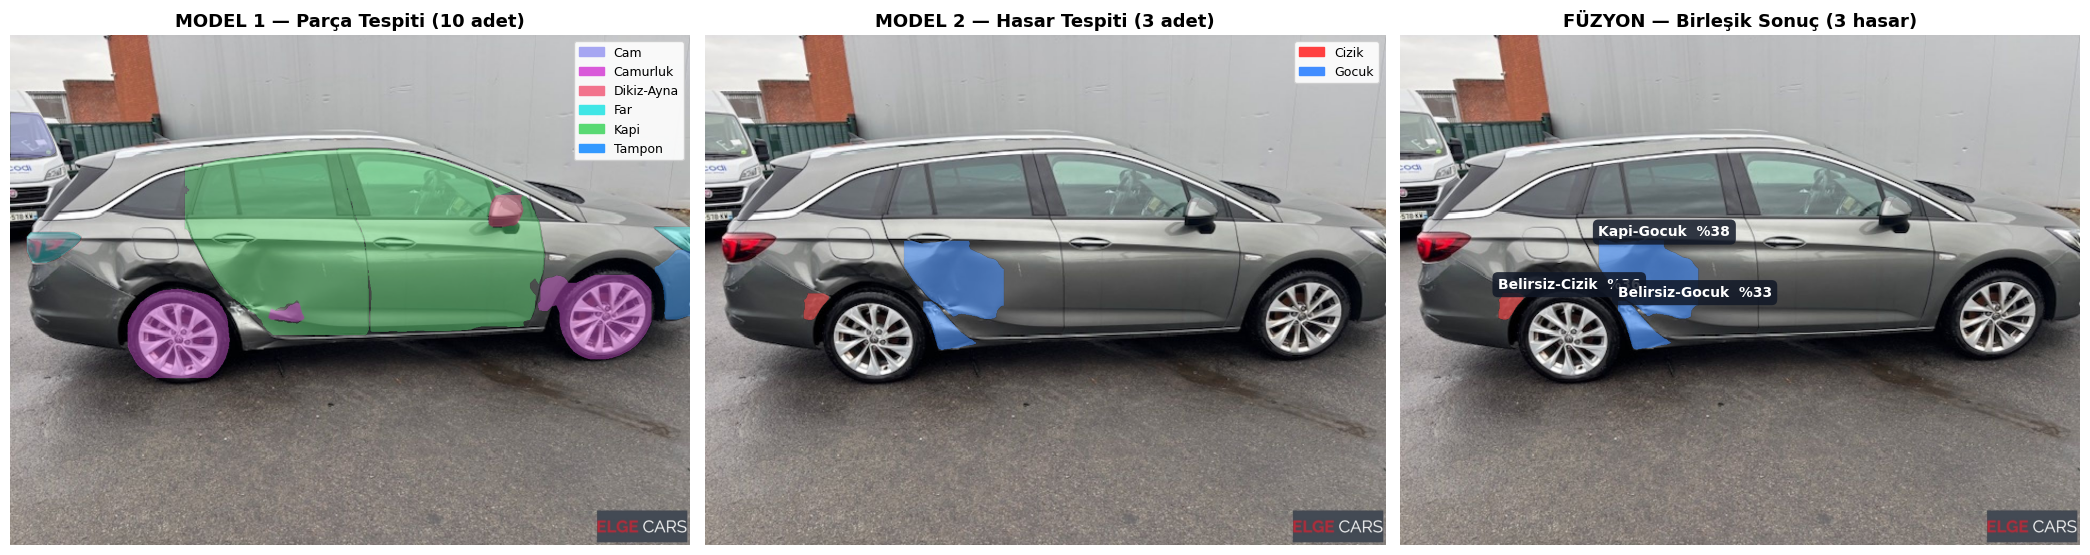


📋 TESPİT SONUÇLARI
1. Kapi-Gocuk                güven: % 37.8 | alan: %1.69 | örtüşme: %94
2. Belirsiz-Cizik            güven: % 36.1 | alan: %0.14 | örtüşme: %0
3. Belirsiz-Gocuk            güven: % 32.9 | alan: %0.34 | örtüşme: %0
💾 /content/drive/MyDrive/tez_arac_hasar/ciktilar/gorseller/analiz_17617474321707386526-4.png


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🖼️ HÜCRE 8: 3 PANELLİ GÖRSELLEŞTİRME
# ═══════════════════════════════════════════════════════════════════════════════
#
# Panel 1 → Model 1: Tespit edilen parçalar
# Panel 2 → Model 2: Tespit edilen hasarlar
# Panel 3 → FÜZYON: "Tampon-Kirik" etiketleriyle birleşik sonuç
#
# 🎛️ TEST_GORSEL:
#    None                → test setinden rastgele seç
#    '/content/foto.jpg' → kendi dosyan
#    'https://...'       → internetten
# ═══════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import numpy as np, requests, io, random, os, cv2
from pathlib import Path

TEST_GORSEL = '/content/17617474321707386526-4.jpg'

# ─── GÖRSELİ YÜKLE ────────────────────────────────────────────────────────────
if TEST_GORSEL is None:
    if 'DATASET_DIR' not in globals() or DATASET_DIR is None:
        raise RuntimeError('❌ DATASET_DIR yok. TEST_GORSEL = "/content/1761729430677043775-6.jpg" yaz.')
    td = os.path.join(DATASET_DIR, 'test', 'images')
    adaylar = list(Path(td).glob('*.*'))
    if not adaylar:
        raise RuntimeError(f'❌ {td} boş!')
    TEST_GORSEL = str(random.choice(adaylar))
    print(f'🎲 Rastgele: {os.path.basename(TEST_GORSEL)}')

if str(TEST_GORSEL).startswith('http'):
    r = requests.get(TEST_GORSEL, timeout=15, headers={'User-Agent':'Mozilla/5.0'})
    img_np = np.array(Image.open(io.BytesIO(r.content)).convert('RGB'))
else:
    img_np = np.array(Image.open(TEST_GORSEL).convert('RGB'))

print(f'📐 Boyut: {img_np.shape[1]}x{img_np.shape[0]}')

# ─── ANALİZ ───────────────────────────────────────────────────────────────────
print('\n🔍 Analiz ediliyor...')
sonuc = fuzyon_analiz(img_np, verbose=True)

# ─── ÇİZ ──────────────────────────────────────────────────────────────────────
def overlay_ciz(ax, img, ogeler, renk_map, anahtar, alpha=0.45):
    ax.imshow(img)
    H, W = img.shape[:2]
    ov = np.zeros((H, W, 4), dtype=np.float32)
    for o in ogeler:
        c = renk_map.get(o[anahtar], [0.5,0.5,0.5])
        ov[o['mask'], :3] = c
        ov[o['mask'],  3] = alpha
    ax.imshow(ov); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# Panel 1
overlay_ciz(axes[0], img_np, sonuc['parcalar'], PARCA_RENK, 'parca')
axes[0].set_title(f'MODEL 1 — Parça Tespiti ({len(sonuc["parcalar"])} adet)',
                  fontsize=13, fontweight='bold')
if sonuc['parcalar']:
    seen = {p['parca'] for p in sonuc['parcalar']}
    axes[0].legend(handles=[mpatches.Patch(color=PARCA_RENK.get(s,[.5]*3), label=s)
                            for s in sorted(seen)],
                   loc='upper right', fontsize=9, framealpha=0.9)

# Panel 2
overlay_ciz(axes[1], img_np, sonuc['hasarlar'], HASAR_RENK, 'hasar', alpha=0.55)
axes[1].set_title(f'MODEL 2 — Hasar Tespiti ({len(sonuc["hasarlar"])} adet)',
                  fontsize=13, fontweight='bold')
if sonuc['hasarlar']:
    seen = {h['hasar'] for h in sonuc['hasarlar']}
    axes[1].legend(handles=[mpatches.Patch(color=HASAR_RENK.get(s,[.5]*3), label=s)
                            for s in sorted(seen)],
                   loc='upper right', fontsize=9, framealpha=0.9)

# Panel 3 — Füzyon
axes[2].imshow(img_np)
H, W = img_np.shape[:2]
ov = np.zeros((H, W, 4), dtype=np.float32)
for b in sonuc['birlesik']:
    c = HASAR_RENK.get(b['hasar'], [0.5,0.5,0.5])
    ov[b['mask'], :3] = c
    ov[b['mask'],  3] = 0.6
axes[2].imshow(ov)
for b in sonuc['birlesik']:
    x1, y1, x2, y2 = b['bbox']
    axes[2].text(x1, max(y1-8, 12), f"{b['etiket']}  %{b['guven']*100:.0f}",
                 fontsize=10, fontweight='bold', color='white',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='#111827',
                           alpha=0.85, edgecolor='none'))
axes[2].set_title(f'FÜZYON — Birleşik Sonuç ({len(sonuc["birlesik"])} hasar)',
                  fontsize=13, fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
kayit = f'{GORSEL_DIR}/analiz_{os.path.basename(str(TEST_GORSEL)).split(".")[0]}.png'
plt.savefig(kayit, dpi=180, bbox_inches='tight')
plt.show()

# ─── METİN ÖZET ───────────────────────────────────────────────────────────────
print('\n' + '=' * 70)
print('📋 TESPİT SONUÇLARI')
print('=' * 70)
if sonuc['birlesik']:
    for i, b in enumerate(sonuc['birlesik'], 1):
        print(f'{i}. {b["etiket"]:25s} güven: %{b["guven"]*100:5.1f} | '
              f'alan: %{b["alan_yuzde"]:.2f} | örtüşme: %{b["ortusme"]*100:.0f}')
else:
    print('   Hasar tespit edilmedi.')
print('=' * 70)
print(f'💾 {kayit}')


---
## 📄 HÜCRE 9: TRAMER Raporu (PDF)

Sigorta ekspertiz belgesi formatında, Türkçe karakter destekli PDF.


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📄 HÜCRE 9: TRAMER RAPORU ÜRETİCİ
# ═══════════════════════════════════════════════════════════════════════════════
#
# 📋 RAPOR İÇERİĞİ:
#    1. Başlık + belge no + tarih
#    2. Araç bilgileri (plaka, marka, model — manuel)
#    3. Hasar tablosu (Parça | Hasar | Alan | Güven | Durum)
#    4. Analiz görseli (gömülü)
#    5. Sistem bilgisi + yasal not
#
# 🔤 TÜRKÇE KARAKTER: DejaVuSans indirilir (ReportLab varsayılanında ğ/ş/ı yok)
#
# 📊 TABLO KAYNAKLARI:
#    Parça  → Model 1  |  Hasar → Model 2
#    Alan   → Model 2 maskesinin piksel oranı
#    Güven  → hasar_conf × parça_conf
#    Durum  → ≥%70 Kesin, ≥%45 Olası, altı Şüpheli
# ═══════════════════════════════════════════════════════════════════════════════

import os, urllib.request
from datetime import datetime
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import mm
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import (SimpleDocTemplate, Paragraph, Spacer, Table,
                                TableStyle, Image as RLImage)
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from PIL import Image as PILImage
import numpy as np

# ─── TÜRKÇE FONT ──────────────────────────────────────────────────────────────
FONT_DIR = '/content/fonts'
os.makedirs(FONT_DIR, exist_ok=True)
FONT_REG  = f'{FONT_DIR}/DejaVuSans.ttf'
FONT_BOLD = f'{FONT_DIR}/DejaVuSans-Bold.ttf'

if not os.path.exists(FONT_REG):
    print('📥 Türkçe font hazırlanıyor...')
    try:
        base = 'https://raw.githubusercontent.com/dejavu-fonts/dejavu-fonts/master/build/ttf'
        urllib.request.urlretrieve(f'{base}/DejaVuSans.ttf', FONT_REG)
        urllib.request.urlretrieve(f'{base}/DejaVuSans-Bold.ttf', FONT_BOLD)
    except Exception:
        # Yedek: sistem fontunu kullan
        import subprocess, shutil as _sh
        subprocess.run(['apt-get', 'install', '-y', 'fonts-dejavu-core', '-qq'],
                       capture_output=True)
        _sys = '/usr/share/fonts/truetype/dejavu'
        _sh.copy(f'{_sys}/DejaVuSans.ttf', FONT_REG)
        _sh.copy(f'{_sys}/DejaVuSans-Bold.ttf', FONT_BOLD)

pdfmetrics.registerFont(TTFont('DejaVu',      FONT_REG))
pdfmetrics.registerFont(TTFont('DejaVu-Bold', FONT_BOLD))
print('✅ Türkçe font hazır')


def tramer_raporu_olustur(sonuc, img_np, arac_bilgi=None, dosya_adi=None):
    """Füzyon sonucundan TRAMER formatında PDF üretir."""
    arac_bilgi = arac_bilgi or {}
    simdi = datetime.now()
    belge_no = arac_bilgi.get('hasar_no') or f"HT-{simdi.strftime('%Y%m%d-%H%M%S')}"
    dosya_adi = dosya_adi or f'{RAPOR_DIR}/tramer_{belge_no}.pdf'

    ss = getSampleStyleSheet()
    st_b  = ParagraphStyle('B', parent=ss['Title'], fontName='DejaVu-Bold',
                           fontSize=17, textColor=colors.HexColor('#0f172a'),
                           spaceAfter=2, alignment=1)
    st_a  = ParagraphStyle('A', parent=ss['Normal'], fontName='DejaVu',
                           fontSize=9.5, textColor=colors.HexColor('#64748b'),
                           alignment=1, spaceAfter=12)
    st_h  = ParagraphStyle('H', parent=ss['Heading2'], fontName='DejaVu-Bold',
                           fontSize=11.5, textColor=colors.HexColor('#1e40af'),
                           spaceBefore=13, spaceAfter=6)
    st_p  = ParagraphStyle('P', parent=ss['Normal'], fontName='DejaVu',
                           fontSize=9, leading=13)
    st_k  = ParagraphStyle('K', parent=ss['Normal'], fontName='DejaVu',
                           fontSize=7.5, textColor=colors.HexColor('#64748b'),
                           leading=11)

    doc = SimpleDocTemplate(dosya_adi, pagesize=A4,
                            leftMargin=18*mm, rightMargin=18*mm,
                            topMargin=15*mm, bottomMargin=15*mm)
    story = []

    story.append(Paragraph('ARAÇ HASAR TESPİT RAPORU', st_b))
    story.append(Paragraph('Yapay Zekâ Destekli Otomatik Ekspertiz Sistemi', st_a))

    # 0. Belge bilgileri
    t0 = Table([
        ['Belge No', belge_no, 'Düzenleme Tarihi', simdi.strftime('%d.%m.%Y %H:%M')],
        ['Poliçe No', arac_bilgi.get('police_no','—'), 'Rapor Türü', 'Otomatik Ön Tespit'],
    ], colWidths=[32*mm, 46*mm, 38*mm, 46*mm])
    t0.setStyle(TableStyle([
        ('FONTNAME',(0,0),(-1,-1),'DejaVu'),
        ('FONTNAME',(0,0),(0,-1),'DejaVu-Bold'),
        ('FONTNAME',(2,0),(2,-1),'DejaVu-Bold'),
        ('FONTSIZE',(0,0),(-1,-1),8.5),
        ('BACKGROUND',(0,0),(0,-1),colors.HexColor('#f1f5f9')),
        ('BACKGROUND',(2,0),(2,-1),colors.HexColor('#f1f5f9')),
        ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
        ('VALIGN',(0,0),(-1,-1),'MIDDLE'),
        ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5),
    ]))
    story.append(t0)

    # 1. Araç
    story.append(Paragraph('1. ARAÇ BİLGİLERİ', st_h))
    t1 = Table([
        ['Plaka', arac_bilgi.get('plaka','—'), 'Marka', arac_bilgi.get('marka','—')],
        ['Model', arac_bilgi.get('model','—'), 'Model Yılı', str(arac_bilgi.get('yil','—'))],
        ['Şasi No', arac_bilgi.get('sase','—'), 'Renk', arac_bilgi.get('renk','—')],
    ], colWidths=[32*mm, 46*mm, 38*mm, 46*mm])
    t1.setStyle(TableStyle([
        ('FONTNAME',(0,0),(-1,-1),'DejaVu'),
        ('FONTNAME',(0,0),(0,-1),'DejaVu-Bold'),
        ('FONTNAME',(2,0),(2,-1),'DejaVu-Bold'),
        ('FONTSIZE',(0,0),(-1,-1),8.5),
        ('BACKGROUND',(0,0),(0,-1),colors.HexColor('#f8fafc')),
        ('BACKGROUND',(2,0),(2,-1),colors.HexColor('#f8fafc')),
        ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
        ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5),
    ]))
    story.append(t1)

    # 2. Hasarlar
    story.append(Paragraph('2. TESPİT EDİLEN HASARLAR', st_h))
    birlesik = sonuc['birlesik']
    if birlesik:
        veri = [['#','Parça','Hasar Tipi','Alan (%)','Güven (%)','Durum']]
        for i, b in enumerate(birlesik, 1):
            durum = 'Kesin' if b['guven'] >= 0.70 else ('Olası' if b['guven'] >= 0.45 else 'Şüpheli')
            veri.append([str(i), b['parca'], b['hasar'],
                         f"{b['alan_yuzde']:.2f}", f"{b['guven']*100:.1f}", durum])

        th = Table(veri, colWidths=[10*mm,38*mm,32*mm,26*mm,26*mm,30*mm])
        stil = [
            ('FONTNAME',(0,0),(-1,0),'DejaVu-Bold'),
            ('FONTNAME',(0,1),(-1,-1),'DejaVu'),
            ('FONTSIZE',(0,0),(-1,-1),8.5),
            ('BACKGROUND',(0,0),(-1,0),colors.HexColor('#1e40af')),
            ('TEXTCOLOR',(0,0),(-1,0),colors.white),
            ('ALIGN',(0,0),(0,-1),'CENTER'),
            ('ALIGN',(3,0),(-1,-1),'CENTER'),
            ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
            ('VALIGN',(0,0),(-1,-1),'MIDDLE'),
            ('TOPPADDING',(0,0),(-1,-1),5),('BOTTOMPADDING',(0,0),(-1,-1),5),
        ]
        for i in range(1, len(veri)):
            if i % 2 == 0:
                stil.append(('BACKGROUND',(0,i),(-1,i),colors.HexColor('#f8fafc')))
        th.setStyle(TableStyle(stil))
        story.append(th)

        ta = sum(b['alan_yuzde'] for b in birlesik)
        ps = ', '.join(sorted({b['parca'] for b in birlesik}))
        ts = ', '.join(sorted({b['hasar'] for b in birlesik}))
        story.append(Spacer(1, 7))
        story.append(Paragraph(
            f'<b>Özet:</b> Toplam <b>{len(birlesik)}</b> hasar tespit edildi. '
            f'Etkilenen parçalar: <b>{ps}</b>. Hasar tipleri: <b>{ts}</b>. '
            f'Toplam hasarlı alan: <b>%{ta:.2f}</b>.', st_p))
    else:
        story.append(Paragraph('Görselde herhangi bir hasar tespit edilmemiştir.', st_p))

    # 3. Görsel
    story.append(Paragraph('3. GÖRSEL ANALİZ', st_h))
    vis = img_np.astype(np.float32).copy()
    for b in birlesik:
        c = np.array(HASAR_RENK.get(b['hasar'], [0.5,0.5,0.5])) * 255
        vis[b['mask']] = vis[b['mask']] * 0.42 + c * 0.58
    vis = vis.astype(np.uint8)

    tmp = '/content/_rapor_gorsel.jpg'
    PILImage.fromarray(vis).save(tmp, 'JPEG', quality=88)
    ih, iw = vis.shape[:2]
    oran = min(160*mm/iw, 105*mm/ih)
    story.append(RLImage(tmp, width=iw*oran, height=ih*oran))
    story.append(Spacer(1, 4))
    story.append(Paragraph(f'Renk kodları: {" | ".join(HASAR_RENK)}', st_k))

    # 4. Sistem
    story.append(Paragraph('4. SİSTEM BİLGİSİ', st_h))
    t4 = Table([
        ['Parça Tespit Modeli', 'YOLOv11m-seg (Carparts-Seg)'],
        ['Hasar Tespit Modeli', EN_IYI.get('ad','—')],
        ['Hasar Modeli mAP50',  f"{EN_IYI.get('mask_mAP50',0):.4f}"],
        ['İşlem Süresi',        f"~{EN_IYI.get('inference_ms',0):.0f} ms/görsel"],
        ['Görüntü Çözünürlüğü', f"{sonuc['goruntu_boyut'][0]} x {sonuc['goruntu_boyut'][1]} px"],
    ], colWidths=[58*mm, 104*mm])
    t4.setStyle(TableStyle([
        ('FONTNAME',(0,0),(-1,-1),'DejaVu'),
        ('FONTNAME',(0,0),(0,-1),'DejaVu-Bold'),
        ('FONTSIZE',(0,0),(-1,-1),8),
        ('BACKGROUND',(0,0),(0,-1),colors.HexColor('#f8fafc')),
        ('GRID',(0,0),(-1,-1),0.4,colors.HexColor('#cbd5e1')),
        ('TOPPADDING',(0,0),(-1,-1),4),('BOTTOMPADDING',(0,0),(-1,-1),4),
    ]))
    story.append(t4)

    story.append(Spacer(1, 10))
    story.append(Paragraph(
        '<b>ÖNEMLİ AÇIKLAMA:</b> Bu rapor yapay zekâ tabanlı görüntü analiz sistemi '
        'tarafından otomatik olarak üretilmiştir ve <b>ön değerlendirme</b> niteliğindedir. '
        'Nihai hasar tespiti, onarım kapsamı ve tazminat tutarı yetkili eksper incelemesi '
        'sonucunda belirlenir. Sistem çıktıları yalnızca eksper iş akışını hızlandırmak '
        'amacıyla referans olarak kullanılmalıdır. Görüntü kalitesi, çekim açısı ve ışık '
        'koşulları tespit doğruluğunu etkileyebilir.', st_k))

    doc.build(story)
    return dosya_adi


# ─── ÖRNEK RAPOR ──────────────────────────────────────────────────────────────
print('\n📄 Örnek rapor üretiliyor...')
pdf = tramer_raporu_olustur(
    sonuc, img_np,
    arac_bilgi={
        'plaka':'34 ABC 123', 'marka':'Volkswagen', 'model':'Passat',
        'yil':2020, 'renk':'Beyaz', 'sase':'WVWZZZ3CZLE000000',
        'police_no':'POL-2026-004521',
    })
print(f'✅ {pdf}')

try:
    from google.colab import files
    files.download(pdf)
except Exception:
    pass


📥 Türkçe font hazırlanıyor...
✅ Türkçe font hazır

📄 Örnek rapor üretiliyor...
✅ /content/drive/MyDrive/tez_arac_hasar/ciktilar/raporlar/tramer_HT-20260805-211821.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## 📦 HÜCRE 10: Toplu İşlem + Excel Özet


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📦 HÜCRE 10: TOPLU İŞLEM
# ═══════════════════════════════════════════════════════════════════════════════
#
# 🎯 NE YAPAR?
#    - Klasördeki tüm görselleri işler
#    - Her biri için analiz görseli + TRAMER PDF üretir
#    - Sonuçları Excel'e yazar (3 sayfa: detay, matris, özet)
#    - Hepsini ZIP'ler
#
# 🎛️ AYARLAR:
#    KAYNAK_KLASOR : İşlenecek görsellerin klasörü
#    LIMIT         : Kaç görsel (None = hepsi)
#    PDF_URET      : Her görsel için PDF üretilsin mi
# ═══════════════════════════════════════════════════════════════════════════════

import pandas as pd, shutil, time, os
import numpy as np
from pathlib import Path
from PIL import Image

KAYNAK_KLASOR = os.path.join(DATASET_DIR, 'test', 'images') if DATASET_DIR else '/content/fotograflar'
LIMIT       = 20        # None = hepsi
PDF_URET    = True
GORSEL_URET = True

gorseller = sorted([p for p in Path(KAYNAK_KLASOR).glob('*.*')
                    if p.suffix.lower() in ['.jpg','.jpeg','.png']])
if LIMIT:
    gorseller = gorseller[:LIMIT]

print('=' * 70)
print(f'📦 TOPLU İŞLEM — {len(gorseller)} görsel')
print('=' * 70)
print(f'   Kaynak: {KAYNAK_KLASOR}')
print(f'   PDF   : {PDF_URET}  |  Görsel: {GORSEL_URET}')
print('=' * 70)

kayitlar = []
t0 = time.time()

for i, gp in enumerate(gorseller, 1):
    try:
        img = np.array(Image.open(gp).convert('RGB'))
        s = fuzyon_analiz(img)

        if s['birlesik']:
            for b in s['birlesik']:
                kayitlar.append({
                    'Dosya':      gp.name,
                    'Etiket':     b['etiket'],
                    'Parça':      b['parca'],
                    'Hasar Tipi': b['hasar'],
                    'Güven (%)':  round(b['guven']*100, 1),
                    'Alan (%)':   round(b['alan_yuzde'], 3),
                    'Örtüşme(%)': round(b['ortusme']*100, 1),
                })
        else:
            kayitlar.append({'Dosya': gp.name, 'Etiket':'—', 'Parça':'—',
                             'Hasar Tipi':'Tespit yok', 'Güven (%)':0,
                             'Alan (%)':0, 'Örtüşme(%)':0})

        if GORSEL_URET and s['birlesik']:
            vis = img.astype(np.float32).copy()
            for b in s['birlesik']:
                c = np.array(HASAR_RENK.get(b['hasar'], [0.5]*3)) * 255
                vis[b['mask']] = vis[b['mask']]*0.42 + c*0.58
            Image.fromarray(vis.astype(np.uint8)).save(
                f'{GORSEL_DIR}/{gp.stem}_analiz.jpg', 'JPEG', quality=88)

        if PDF_URET:
            tramer_raporu_olustur(s, img,
                arac_bilgi={'hasar_no': f'HT-{gp.stem[:20]}'},
                dosya_adi=f'{RAPOR_DIR}/rapor_{gp.stem}.pdf')

        if i % 5 == 0 or i == len(gorseller):
            gec = time.time() - t0
            hiz = i / gec if gec > 0 else 0
            kal = (len(gorseller)-i) / hiz if hiz > 0 else 0
            print(f'   {i}/{len(gorseller)} | {hiz:.2f} görsel/sn | ~{kal:.0f}sn kaldı')

    except Exception as e:
        print(f'   ⚠️ {gp.name}: {str(e)[:80]}')

# ─── EXCEL ────────────────────────────────────────────────────────────────────
df_s = pd.DataFrame(kayitlar)
excel_yol = f'{OUTPUT_DIR}/toplu_analiz_sonuclari.xlsx'

with pd.ExcelWriter(excel_yol, engine='openpyxl') as w:
    df_s.to_excel(w, sheet_name='Tüm Tespitler', index=False)
    gecerli = df_s[df_s['Hasar Tipi'] != 'Tespit yok']
    if not gecerli.empty:
        pd.crosstab(gecerli['Parça'], gecerli['Hasar Tipi'],
                    margins=True, margins_name='TOPLAM'
                    ).to_excel(w, sheet_name='Parça-Hasar Matrisi')
        gecerli.groupby('Etiket').agg(
            Adet=('Etiket','count'),
            Ort_Guven=('Güven (%)','mean'),
            Ort_Alan=('Alan (%)','mean'),
        ).round(2).sort_values('Adet', ascending=False
        ).to_excel(w, sheet_name='Etiket Özeti')

print('\n' + '=' * 70)
print('✅ TOPLU İŞLEM TAMAMLANDI')
print('=' * 70)
print(f'   İşlenen görsel : {len(gorseller)}')
print(f'   Toplam tespit  : {len(df_s[df_s["Hasar Tipi"] != "Tespit yok"])}')
print(f'   Süre           : {(time.time()-t0)/60:.1f} dk')
print(f'\n   📊 {excel_yol}')
print(f'   📄 {RAPOR_DIR}')
print(f'   🖼️  {GORSEL_DIR}')

gecerli = df_s[df_s['Hasar Tipi'] != 'Tespit yok']
if not gecerli.empty:
    print(f'\n🏷️  EN SIK ETİKETLER:')
    for et, ad in gecerli['Etiket'].value_counts().head(10).items():
        print(f'   {et:28s}: {ad}')

# ─── ZIP ──────────────────────────────────────────────────────────────────────
print('\n📦 Arşivleniyor...')
zip_yol = shutil.make_archive('/content/tez_ciktilari', 'zip', OUTPUT_DIR)
print(f'✅ {zip_yol}')

try:
    from google.colab import files
    files.download(zip_yol)
except Exception:
    print('   (Colab dışı — manuel indir)')


📦 TOPLU İŞLEM — 0 görsel
   Kaynak: /content/fotograflar
   PDF   : True  |  Görsel: True


KeyError: 'Hasar Tipi'

---
# 📋 Hızlı Referans

## 🔨 İlk Kez Çalıştırma

```
0 → 1 → 2 → 3 → 4 → 4A → 4D → 4B → 4C → 5 → 6 → 6B
```

⚠️ **Hücre 1'de API_KEY doldurmayı unutma.**

## ⚡ Model Hazırsa

```
0 → 1 → 6D → 7 → 8 / 9 / 10
```

---

## 🔧 Sorun Giderme

| Hata | Çözüm |
|---|---|
| `CUDA out of memory` | Hücre 1'de batch'i yarıya indir (8→4) |
| `Version yok` | `ZORLA_YENI_VERSION = True` |
| `Hiçbir sınıf eşleşmedi` | Çıktıdaki isimleri `HASAR_MAP`'e ekle |
| `en_iyi_id is not defined` | Önce Hücre 6'yı çalıştır |
| Disk dolu | `ORIJINALI_TUT = False` |
| Görseller 640px uyarısı | `ZORLA_YENI_VERSION=True` ile Hücre 4'ü tekrar çalıştır |
| Tiling çok yavaş | `TILE_GRID = (2,2)` yeterli, (3,3) yapma |

---

## 📊 Sonuç Değerlendirme

| Mask mAP50 | Anlamı | Ne yapmalı |
|---|---|---|
| ≥ 0.70 | Çok iyi | K-fold yap, tezi yaz |
| 0.55–0.70 | İyi | K-fold yap (Hücre 6C) |
| 0.40–0.55 | Orta | Confusion matrix'e bak (Hücre 6B) |
| < 0.40 | Zayıf | Etiketleme kalitesini gözden geçir |

---

## 💡 Confusion Matrix Okuma

- **Köşegen yüksek** → model sınıfları doğru ayırıyor ✅
- **Cizik ↔ Gocuk karışımı yüksek** → etiketleme tutarsızlığı olabilir
- **background sütunu yüksek** → model hasarları kaçırıyor (recall düşük)

---

## 📝 Tez Notları

- Harici veri kullandıysan **kaynağa atıf ver** ve birleşimi metodolojide belirt
- Tiling'i "sliced inference / tiling (SAHI, 2022)" olarak referansla
- K-fold sonucunu `mAP50 = 0.58 ± 0.02` formatında yaz
- MSE/RMSE/MAE bu modelde kullanılmaz — 4. modelde (fiyat tahmini) kullanacaksın

---

## 🚧 Henüz Yapılmayanlar (Sonraki Aşama)

| Model | Durum |
|---|---|
| 1 — Parça tespiti | ✅ Bu notebook'ta |
| 2 — Hasar tespiti | ✅ Bu notebook'ta |
| 3 — Şiddet (hafif/orta/ağır) | ❌ Şiddet etiketli veri gerekli |
| 4 — Fiyat tahmini | ❌ Fiyat veri tabanı gerekli (burada MSE/RMSE/MAE kullanılacak) |
